<h1>O projeto</h1>

O  objetivo do estudo é avaliar o impacto do consumo de cafeína na qualidade do sono. Para isso, um dataset contendo dados de 10000 observações foi disponibilizado para que uma análise fosse feita considerando não só o consumo de café, além de outras possíveis variáveis.

O estudo contará com as seguintes etapas:

    1. Análise do Panorama Geral
    2. Obtenção dos dados
    3. Análise Exploratória dos Dados
    4. Preparação dos Dados para os Modelos
    5. Seleção e Treinamento e Aperfeiçoamento de Modelos
    6. Apresentação dos Resultados Finais

<h2>Abaixo estão as descrições de cada variável.</h2>

<table class="portfolio-table">
    <thead>
        <tr>
            <th>Coluna</th>
            <th>Tipo</th>	
            <th>Descrição</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td>ID</td>
            <td>Integer</td>
            <td>Identificador único de cada registro (1–10000).</td>
        </tr>
        <tr>
            <td>Idade</td>
            <td>Integer</td>
            <td>Idade do participante (18 a 80 anos).</td>
        </tr>
        <tr>
            <td>Gênero</td>
            <td>Categorical</td>
            <td>Gênero: Male, Female ou Other.</td>
        </tr>
        <tr>
            <td>País</td>
            <td>Categorical</td>
            <td>País de residência (20 países representados).</td>
        </tr>
        <tr>
            <td>Ingestão de Café</td>
            <td>Float</td>
            <td>Consumo diário de café em xícaras (0 a 10).</td>
        </tr>
        <tr>
            <td>Cafeína em Miligramas</td>
            <td>Float</td>
            <td>Estimativa de cafeína ingerida por dia em mg (1 xícara ≈ 95 mg).</td>
        </tr>
        <tr>
            <td>Horas de Sono</td>
            <td>Float</td>
            <td>Média de horas de sono por noite (3 a 10 horas).</td>
        </tr>
        <tr>
            <td>Qualidade do Sono</td>
            <td>Categorical</td>
            <td>Qualidade do sono: Poor, Fair, Good ou Excellent.</td>
        </tr>
        <tr>
            <td>Índice de Massa Corporea</td>
            <td>Float</td>
            <td>Índice de Massa Corporal (15 a 40).</td>
        </tr>
        <tr>
            <td>Frequência Cardíaca</td>
            <td>Integer</td>
            <td>Frequência cardíaca em repouso (50 a 110 bpm).</td>
        </tr>
        <tr>
            <td>Nível de Estresse</td>
            <td>Categorical</td>
            <td>Nível de estresse: Low, Medium ou High.</td>
        </tr>
        <tr>
            <td>Atividade Física</td>
            <td>Float</td>
            <td>Tempo de atividade física semanal em horas (0 a 15).</td>
        </tr>
        <tr>
            <td>Problemas de Saúde</td>
            <td>Categorical</td>
            <td>Condições de saúde: None, Mild, Moderate ou Severe.</td>
        </tr>
        <tr>
            <td>Ocupação</td>
            <td>Categorical</td>
            <td>Ocupação principal: Office, Healthcare, Student, Service, Other.</td>
        </tr>
        <tr>
            <td>Fumante</td>
            <td>Boolean</td>
            <td>Fumante: 0 = Não, 1 = Sim.</td>
        </tr>
        <tr>
            <td>Consumo de Álcool</td>
            <td>Boolean</td>
            <td>Consome álcool: 0 = Não, 1 = Sim.</td>
        </tr>
    </tbody>
</table>


<h1>Análise do Panorama Geral</h1>

Antes de estudarmos as correlações entre as variáveis disponibilziadas no conjunto de dados, é importante entender como os fatores interagem entre si na vida real. Para isso, faremos o uso de um DAG (Directional Acyclic Graph) para ilustrar essas interações:<br><br>

<h3 style='text-align: center;'><b>DAG Para Qualidade do Sono</b></h3>

![DAG](DAG2.jpeg)

Um DAG é um gráfico em que as setas apontam correlações causais entre a variáveis. Tomando o DAG acima como exemplo, "Idade" --> "Problemas de Saúde" implica que conforme as pessoas envelhecem, elas estão sujeitas a apresentarem mais problemas de saúde. 

A construção e a análise de um DAG é bastante útil para tratar viés de variável omitida. O viés de variável omitida ocorre quando uma variável X1' (explicativa) possui relação causal com a variável Y (explicada), mas não faz parte do modelo. O efeito desta variável X1', então, ou passa a ser completamente capturado por outra variável do modelo (digamos, X1), alterando o impacto real da variável X1. Tomando o caso estudado, sabendo que níveis de estresse maiores pioram a qualidade do sono das pessoas, caso ela for omitida do modelo as outras variáveis (incluindo a ingestão de cafeína) apresentarão um impacto maior do que elas realmente representam na realidade, pois incorporarão os efeitos do nível de estresse, a variável omitida.

Mais sobre DAGs: https://mixtape.scunning.com/03-directed_acyclical_graphs

<h1>Obtenção dos Dados</h1>

In [124]:
import warnings

warnings.filterwarnings('ignore')

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import shap
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as imbPipeline
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline as logPipeline
from mord import LogisticAT
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from matplotlib.colors import LinearSegmentedColormap

In [66]:
df = pd.read_csv('synthetic_coffee_health_10000(in).csv')
df.shape

(10000, 16)

<h3>Renomeando variáveis e valores</h3>

In [67]:
colunas = {'ID':'ID', 'Age':'Idade', 'Gender':'Gênero', 'Country':'País', 'Coffee_Intake':'Ingestão_de_café', 'Caffeine_mg':'Cafeína_mg',
       'Sleep_Hours':'Horas_de_sono', 'Sleep_Quality':'Qualidade_do_sono', 'BMI':'IMC', 'Heart_Rate':'Frequência_cardíaca', 'Stress_Level':'Nível_de_estresse',
       'Physical_Activity_Hours':'Atividade_física', 'Health_Issues':'Problemas_de_saúde', 'Occupation':'Ocupação', 'Smoking':'Fumante',
       'Alcohol_Consumption':'Consumo_de_álcool'}

df.rename(columns = colunas, inplace = True)

In [68]:
valores = {
    'Gênero': {
        'Male': 'Masculino', 
        'Female': 'Feminino', 
        'Other': 'Outro'
    },
    'Qualidade_do_sono': {
        'Poor': 'Ruim', 
        'Fair': 'Moderada', 
        'Good': 'Boa', 
        'Excellent': 'Excelente'
    },
    'Nível_de_estresse': {
        'Low': 'Baixo', 
        'Medium': 'Médio', 
        'High': 'Alto'
    },
    'Problemas_de_saúde': {
        'None': 'Nenhum', 
        'Mild': 'Leve', 
        'Moderate': 'Moderado', 
        'Severe': 'Severo'
    },
    'Ocupação': {
        'Office': 'Escritório', 
        'Healthcare': 'Saúde', 
        'Student': 'Estudante', 
        'Service': 'Serviços', 
        'Other': 'Outro'
    },
    'País': {
        'Canada': 'Canadá',
        'India': 'Índia',
        'Norway': 'Noruega',
        'China': 'China',
        'UK': 'Reino Unido',
        'Sweden': 'Suécia',
        'South Korea': 'Coreia do Sul',
        'Finland': 'Finlândia',
        'Italy': 'Itália',
        'Switzerland': 'Suíça',
        'France': 'França',
        'Belgium': 'Bélgica',
        'Australia': 'Austrália',
        'Germany': 'Alemanha',
        'Netherlands': 'Holanda',
        'Spain': 'Espanha',
        'Mexico': 'México',
        'Japan': 'Japão',
        'Brazil': 'Brasil',
        'USA': 'Estados Unidos'
    }
}

In [69]:
df.replace(valores, inplace=True)
df.head()

,ID,Idade,Gênero,País,Ingestão_de_café,Cafeína_mg,Horas_de_sono,Qualidade_do_sono,IMC,Frequência_cardíaca,Nível_de_estresse,Atividade_física,Problemas_de_saúde,Ocupação,Fumante,Consumo_de_álcool
0,1,40,Masculino,Alemanha,3.5,328.1,7.5,Boa,24.9,78,Baixo,14.5,NaN,Outro,0,0
1,2,33,Masculino,Alemanha,1.0,94.1,6.2,Boa,20.0,67,Baixo,11.0,NaN,Serviços,0,0
2,3,42,Masculino,Brasil,5.3,503.7,5.9,Moderada,22.7,59,Médio,11.2,Leve,Escritório,0,0
3,4,53,Masculino,Alemanha,2.6,249.2,7.3,Boa,24.7,71,Baixo,6.6,Leve,Outro,0,0
4,5,32,Feminino,Espanha,3.1,298.0,5.3,Moderada,24.1,76,Médio,8.5,Leve,Estudante,0,1


<h1>Análise Exploratória dos Dados</h1>

In [70]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   Idade                10000 non-null  int64  
 2   Gênero               10000 non-null  object 
 3   País                 10000 non-null  object 
 4   Ingestão_de_café     10000 non-null  float64
 5   Cafeína_mg           10000 non-null  float64
 6   Horas_de_sono        10000 non-null  float64
 7   Qualidade_do_sono    10000 non-null  object 
 8   IMC                  10000 non-null  float64
 9   Frequência_cardíaca  10000 non-null  int64  
 10  Nível_de_estresse    10000 non-null  object 
 11  Atividade_física     10000 non-null  float64
 12  Problemas_de_saúde   4059 non-null   object 
 13  Ocupação             10000 non-null  object 
 14  Fumante              10000 non-null  int64  
 15  Consumo_de_álcool    10000 non-null  

In [71]:
df['Problemas_de_saúde'].fillna('Nenhum', inplace = True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   Idade                10000 non-null  int64  
 2   Gênero               10000 non-null  object 
 3   País                 10000 non-null  object 
 4   Ingestão_de_café     10000 non-null  float64
 5   Cafeína_mg           10000 non-null  float64
 6   Horas_de_sono        10000 non-null  float64
 7   Qualidade_do_sono    10000 non-null  object 
 8   IMC                  10000 non-null  float64
 9   Frequência_cardíaca  10000 non-null  int64  
 10  Nível_de_estresse    10000 non-null  object 
 11  Atividade_física     10000 non-null  float64
 12  Problemas_de_saúde   10000 non-null  object 
 13  Ocupação             10000 non-null  object 
 14  Fumante              10000 non-null  int64  
 15  Consumo_de_álcool    10000 non-null  

In [72]:
df.head(10)

,ID,Idade,Gênero,País,Ingestão_de_café,Cafeína_mg,Horas_de_sono,Qualidade_do_sono,IMC,Frequência_cardíaca,Nível_de_estresse,Atividade_física,Problemas_de_saúde,Ocupação,Fumante,Consumo_de_álcool
0,1,40,Masculino,Alemanha,3.5,328.1,7.5,Boa,24.9,78,Baixo,14.5,Nenhum,Outro,0,0
1,2,33,Masculino,Alemanha,1.0,94.1,6.2,Boa,20.0,67,Baixo,11.0,Nenhum,Serviços,0,0
2,3,42,Masculino,Brasil,5.3,503.7,5.9,Moderada,22.7,59,Médio,11.2,Leve,Escritório,0,0
3,4,53,Masculino,Alemanha,2.6,249.2,7.3,Boa,24.7,71,Baixo,6.6,Leve,Outro,0,0
4,5,32,Feminino,Espanha,3.1,298.0,5.3,Moderada,24.1,76,Médio,8.5,Leve,Estudante,0,1
5,6,32,Masculino,México,3.4,326.4,6.4,Boa,27.0,82,Baixo,8.8,Nenhum,Serviços,0,0
6,7,53,Masculino,França,2.7,252.1,7.8,Boa,24.3,58,Baixo,1.0,Leve,Estudante,1,0
7,8,44,Feminino,Canadá,4.5,423.5,5.5,Moderada,15.8,62,Médio,0.7,Leve,Serviços,1,1
8,9,29,Masculino,Reino Unido,1.7,162.0,7.1,Boa,21.7,60,Baixo,2.2,Nenhum,Serviços,1,1
9,10,41,Feminino,Suíça,4.0,383.2,6.4,Boa,30.4,69,Baixo,11.9,Leve,Escritório,0,0


In [73]:
df.drop_duplicates(inplace = True)

In [74]:
df.shape

(10000, 16)

In [75]:
df.describe()

,ID,Idade,Ingestão_de_café,Cafeína_mg,Horas_de_sono,IMC,Frequência_cardíaca,Atividade_física,Fumante,Consumo_de_álcool
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.00000,10000.000000
mean,5000.50000,34.949100,2.509230,238.411010,6.636220,23.986860,70.617800,7.48704,0.20040,0.300700
std,2886.89568,11.160939,1.450248,137.748815,1.222055,3.906411,9.822951,4.31518,0.40032,0.458585
min,1.00000,18.000000,0.000000,0.000000,3.000000,15.000000,50.000000,0.00000,0.00000,0.000000
25%,2500.75000,26.000000,1.500000,138.750000,5.800000,21.300000,64.000000,3.70000,0.00000,0.000000
50%,5000.50000,34.000000,2.500000,235.400000,6.600000,24.000000,71.000000,7.50000,0.00000,0.000000
75%,7500.25000,43.000000,3.500000,332.025000,7.500000,26.600000,77.000000,11.20000,0.00000,1.000000
max,10000.00000,80.000000,8.200000,780.300000,10.000000,38.200000,109.000000,15.00000,1.00000,1.000000


<h2>Configurando uma Paleta Legível por Daltônicos</h2>

Fonte da visualização das cores: https://davidmathlogic.com/colorblind/#%23D81B60-%2356B4E9-%23FFC107-%23004D40

In [76]:
def colorPalette(show = 1):
    import matplotlib.pyplot as plt
    import matplotlib.patches as patches
    
    palette = {
    'magenta':'#D81B60',
    'blue':'#56B4E9',
    'yellow':'#FFC107',
    'green':'#004D40',
    'orange':'#D55E00'
    }
    if show == 1:
        fig, ax = plt.subplots(figsize=(10,3))
        ax.axis('off')
        for i, (c, h) in enumerate(palette.items()):
            rectangle = patches.Rectangle((i,0), 0.9, 1, color = h)
            ax.add_patch(rectangle)
    
            ax.text(i + 0.45, -0.15, c, ha = 'center', va = 'top', fontsize = 11, weight = 'bold')
    
            ax.text(i + 0.45, -0.35, h, ha='center', va = 'top', fontsize = 10)
    
        ax.set_xlim(0, len(palette))
        ax.set_ylim(-0.5, 1.1)
    
        plt.title('Color-Blind Friendly Palette', fontsize = 14, weight = 'bold', pad = 20)
        plt.show()
            
    return palette

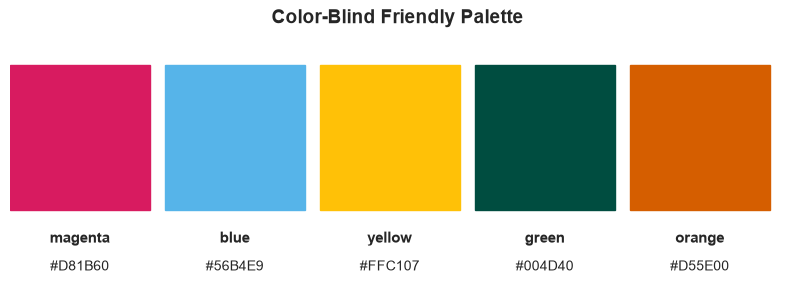

In [77]:
colors = colorPalette();

<h2>Configurando um Heatmap de Correlações</h2>

Uma das formas de entender quais variáveis podem ser interessantes para o modelo é visualizando a correlação entre elas. Para isso, eu criei uma função que constrói um <i>heatmap</i> tricolor (usando uma escala de cores amigável para pessoas com daltonismo) destacando as maiores e menores correlações, a "corrMap".

In [78]:
def corrMap(df, method = 'pearson'):
    
    import seaborn as sns
    import matplotlib.pyplot as plt
    from matplotlib.colors import LinearSegmentedColormap

    colors = colorPalette(0)
    cList = [colors['orange'], '#EEEEEE', colors['green']]
    cmap = LinearSegmentedColormap.from_list('orange_to_green', cList)

    corr = df.corr(numeric_only = True, method = method)

    fig, ax = plt.subplots(figsize=(11,9))

    sns.heatmap(corr, cmap=cmap, annot = True, vmin = -1, vmax = 1)

    plt.show()
    

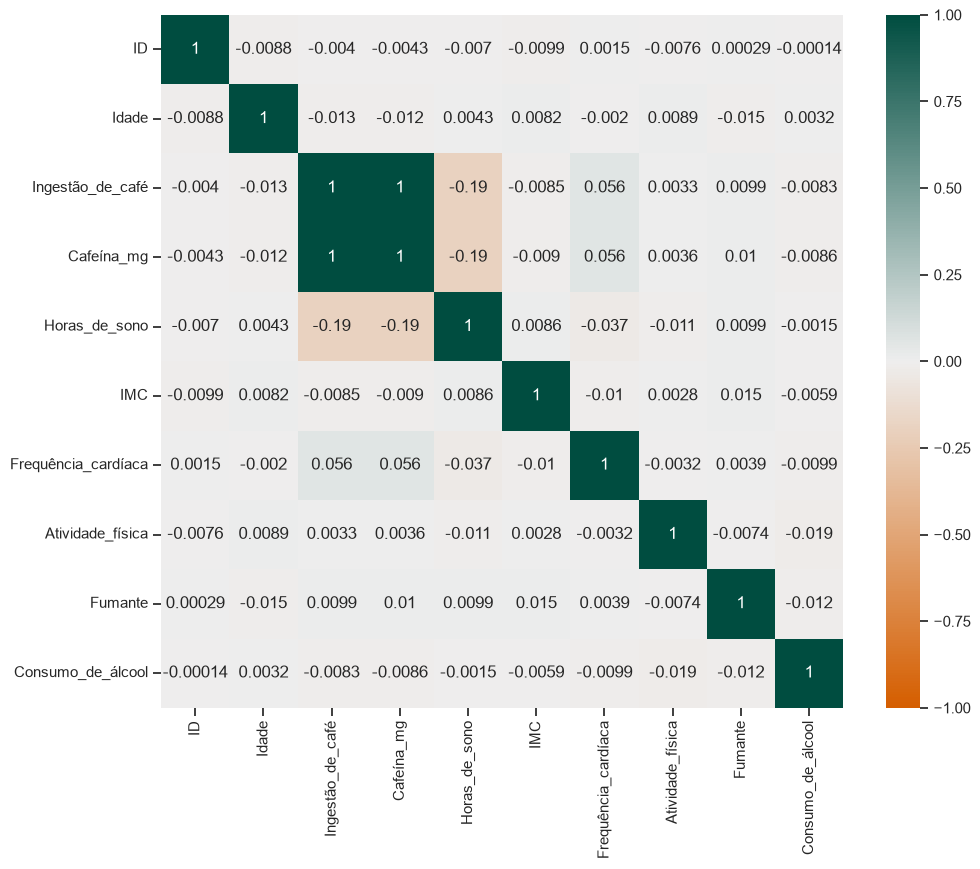

In [79]:
corrMap(df, method = 'spearman')

Como podemos observar, a maior parte das variáveis disponibilizadas possuem baixíssima correlação com a variável alvo, "Horas_de_sono" (que serve de apoio para a variável categórica "Qualidade_do_sono").

Contudo, tendo em mente a discussão acima envolvendo DAGs, se quisermos isolar apenas o efeito do consumo de cafeína na qualidade do sono, teremos que construir o modelo usando algumas variáveis adicionais, mesmo que a correlação seja baixa, a fim de mitigar viés de variável omitida. A prática de incluir as outras variáveis no modelo com o intuito de reduzir viés de variável omitida, no contexto dos DAGs, é conhecido como "fechar os <i>backdoor-paths</i>".

<h2>Estudando as Variáveis Categóricas do Conjunto de Dados</h2>

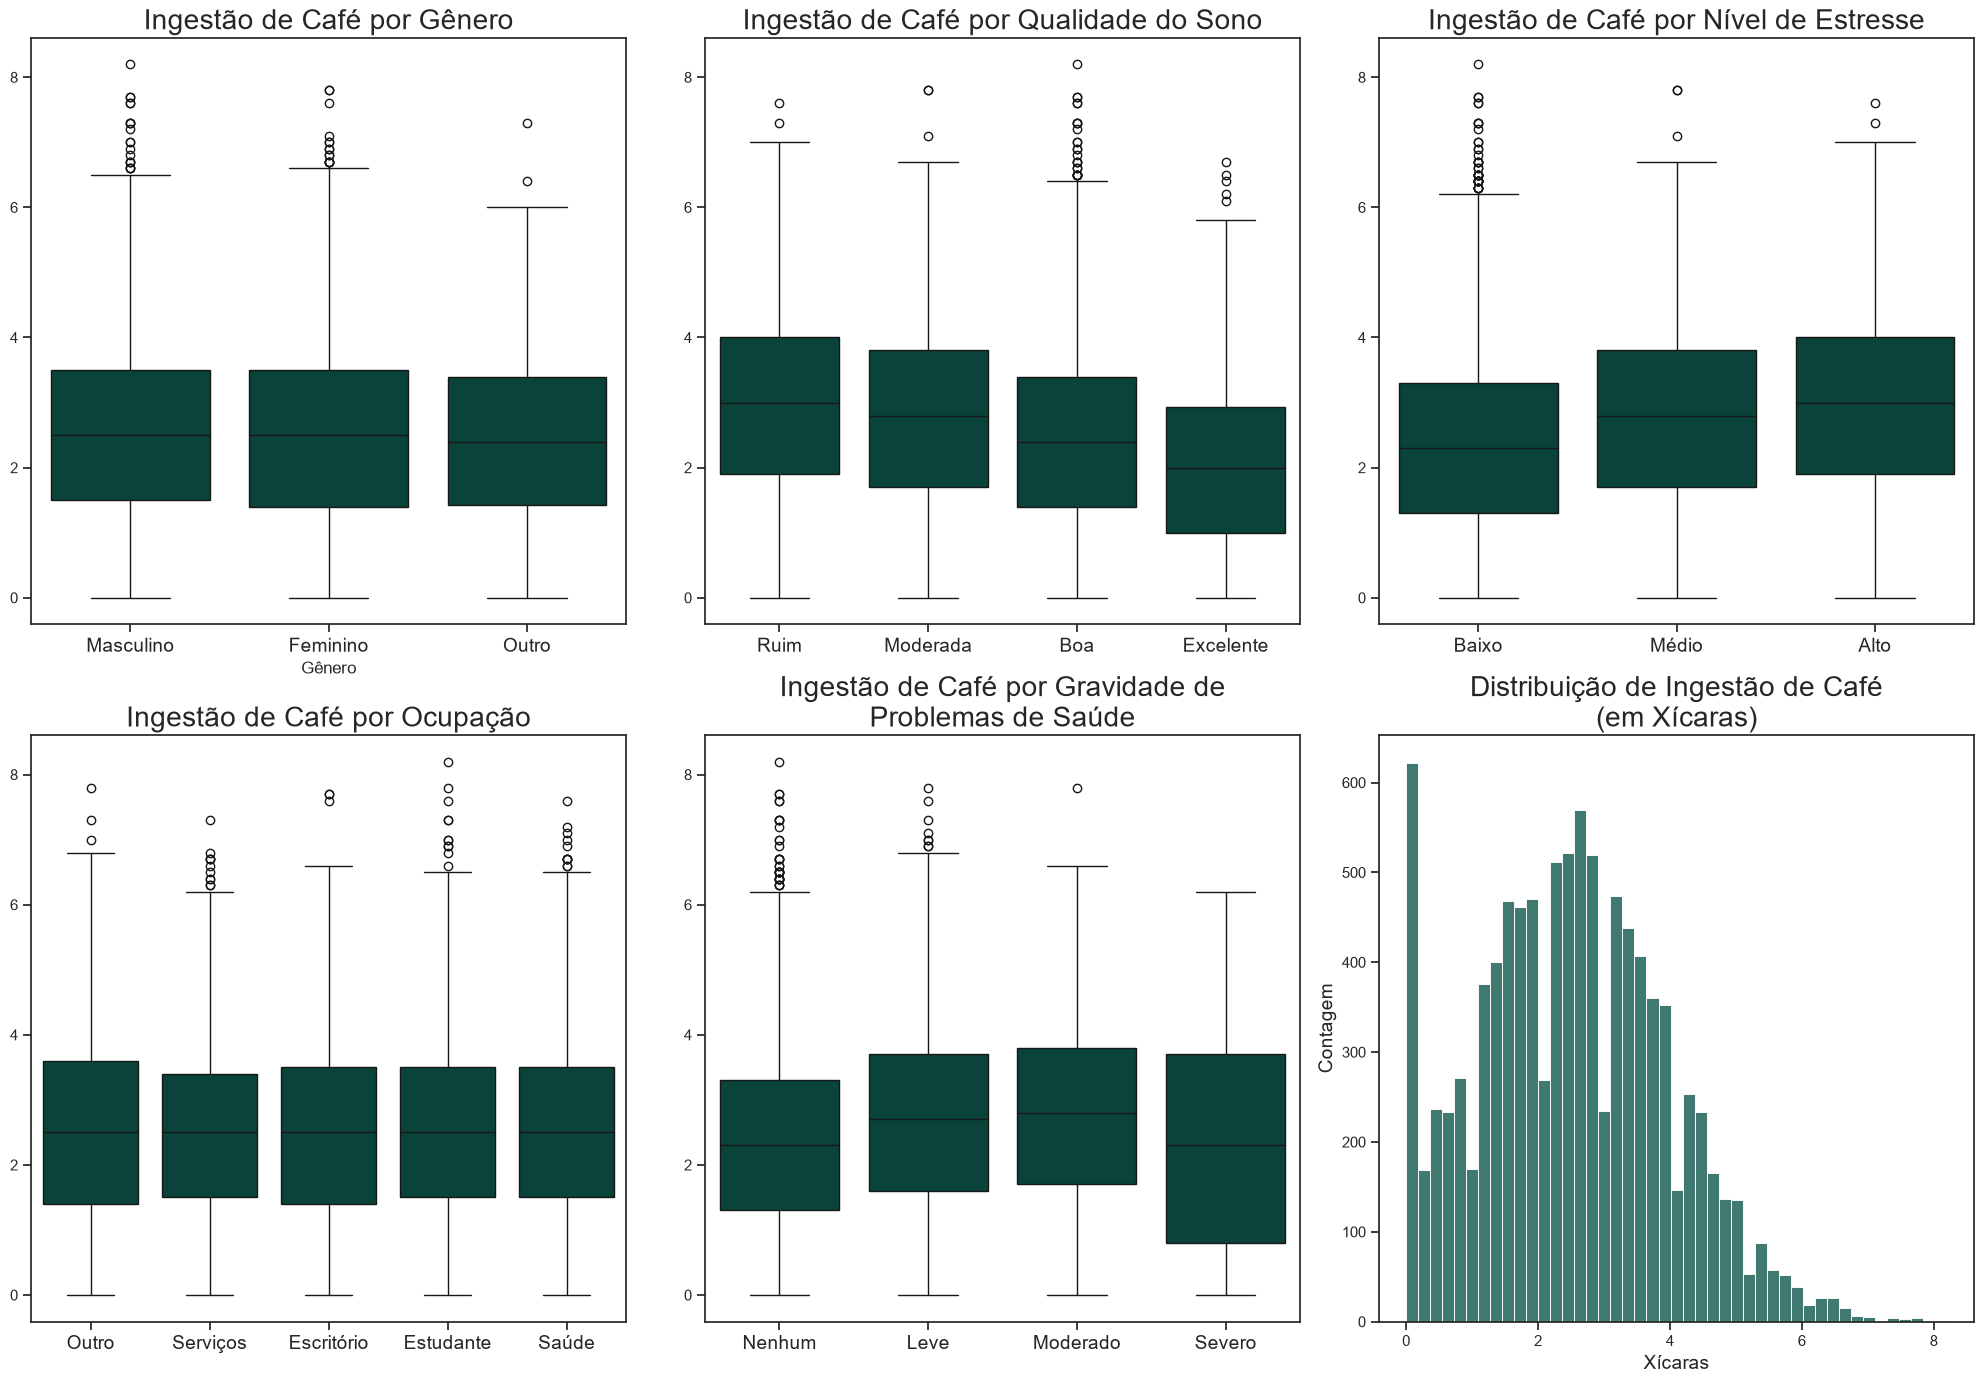

In [80]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(2, 3, figsize = (20, 14))

sns.boxplot(data = df, y = 'Ingestão_de_café', x = 'Gênero', ax = ax[0,0], color = colors['green'])
ax[0,0].set_title('Ingestão de Café por Gênero', fontsize = 20)
ax[0,0].set_ylabel('')
ax[0,0].tick_params(axis = 'x', labelsize = 14)

sns.boxplot(data = df, y = 'Ingestão_de_café', x = 'Qualidade_do_sono', ax = ax[0,1], color = colors['green'], 
            order=['Ruim', 'Moderada', 'Boa', 'Excelente'])
ax[0,1].set_title('Ingestão de Café por Qualidade do Sono', fontsize = 20)
ax[0,1].set_ylabel('')
ax[0,1].tick_params(axis = 'x', labelsize = 14)
ax[0,1].set_xlabel('')

sns.boxplot(data = df, y = 'Ingestão_de_café', x = 'Nível_de_estresse', ax = ax[0,2], color = colors['green'])
ax[0,2].set_title('Ingestão de Café por Nível de Estresse', fontsize = 20)
ax[0,2].set_ylabel('')
ax[0,2].tick_params(axis = 'x', labelsize = 14)
ax[0,2].set_xlabel('')

sns.boxplot(data = df, y = 'Ingestão_de_café', x = 'Ocupação', ax = ax[1,0], color = colors['green'])
ax[1,0].set_title('Ingestão de Café por Ocupação', fontsize = 20)
ax[1,0].set_ylabel('')
ax[1,0].tick_params(axis = 'x', labelsize = 14)
ax[1,0].set_xlabel('')

sns.boxplot(data = df, y = 'Ingestão_de_café', x = 'Problemas_de_saúde', ax = ax[1,1], color = colors['green'])
ax[1,1].set_title('Ingestão de Café por Gravidade de\nProblemas de Saúde', fontsize = 20)
ax[1,1].set_ylabel('')
ax[1,1].tick_params(axis = 'x', labelsize = 14)
ax[1,1].set_xlabel('')

sns.histplot(data = df, x = 'Ingestão_de_café', ax = ax[1,2], color = colors['green'])
ax[1,2].set_title('Distribuição de Ingestão de Café\n(em Xícaras)', fontsize = 20)
ax[1,2].set_ylabel('Contagem', fontsize = 14)
ax[1,2].set_xlabel('Xícaras', fontsize = 14)

plt.tight_layout()
plt.show()

Ao analisar as variáveis categóricas, aparentemente nem diferenças de gênero, nem diferentes ocupações (presentes no conjunto de dados) sugerem possuir alguma correlação com ingestão de café.

Já as as variáveis "Qualidade do Sono", "nível de estresse" e "Gravidade de Problemas de Saúde" parecem possuir alguma correlação com o consumo de café. Os gráficos sugerem que o consumo de café piora a qualidade do sono, aumenta o nível de estresse e piora problemas de saúde (embora o banco de dados não especifique quais problemas de saúde foram considerados no estudo). Pessoas estressadas provavelmente dormem mal durante a noite e acordam cansadas no próximo dia. Para compensar o cansaço, ingerem mais cafeína. A cafeína, por sua vez, por ser um estimulante, pode acabar aumentando o nível de estresse da pessoa, fechando um ciclo:

Nível de Estresse --> Qualidade do Sono --> Consumo de Café --> Nível de Estresse.

Como o conjunto de dados não possibilita que uma modelagem baseada em dados em painel seja feita, o efeito acumulado ao longos dos dias apontado pela relação anterior, em que pessoas cansadas consomem mais café e esse aumento do consumo de café piora a qualidade do sono, fazendo com que ela acorde cansada no próximo dia, será assumido como constante ao longo do tempo, podendo ser desconsiderado.

Por fim, a distribuição de consumo de xícaras de café apresenta uma leve cauda à direita e um truncamento à esquerda.

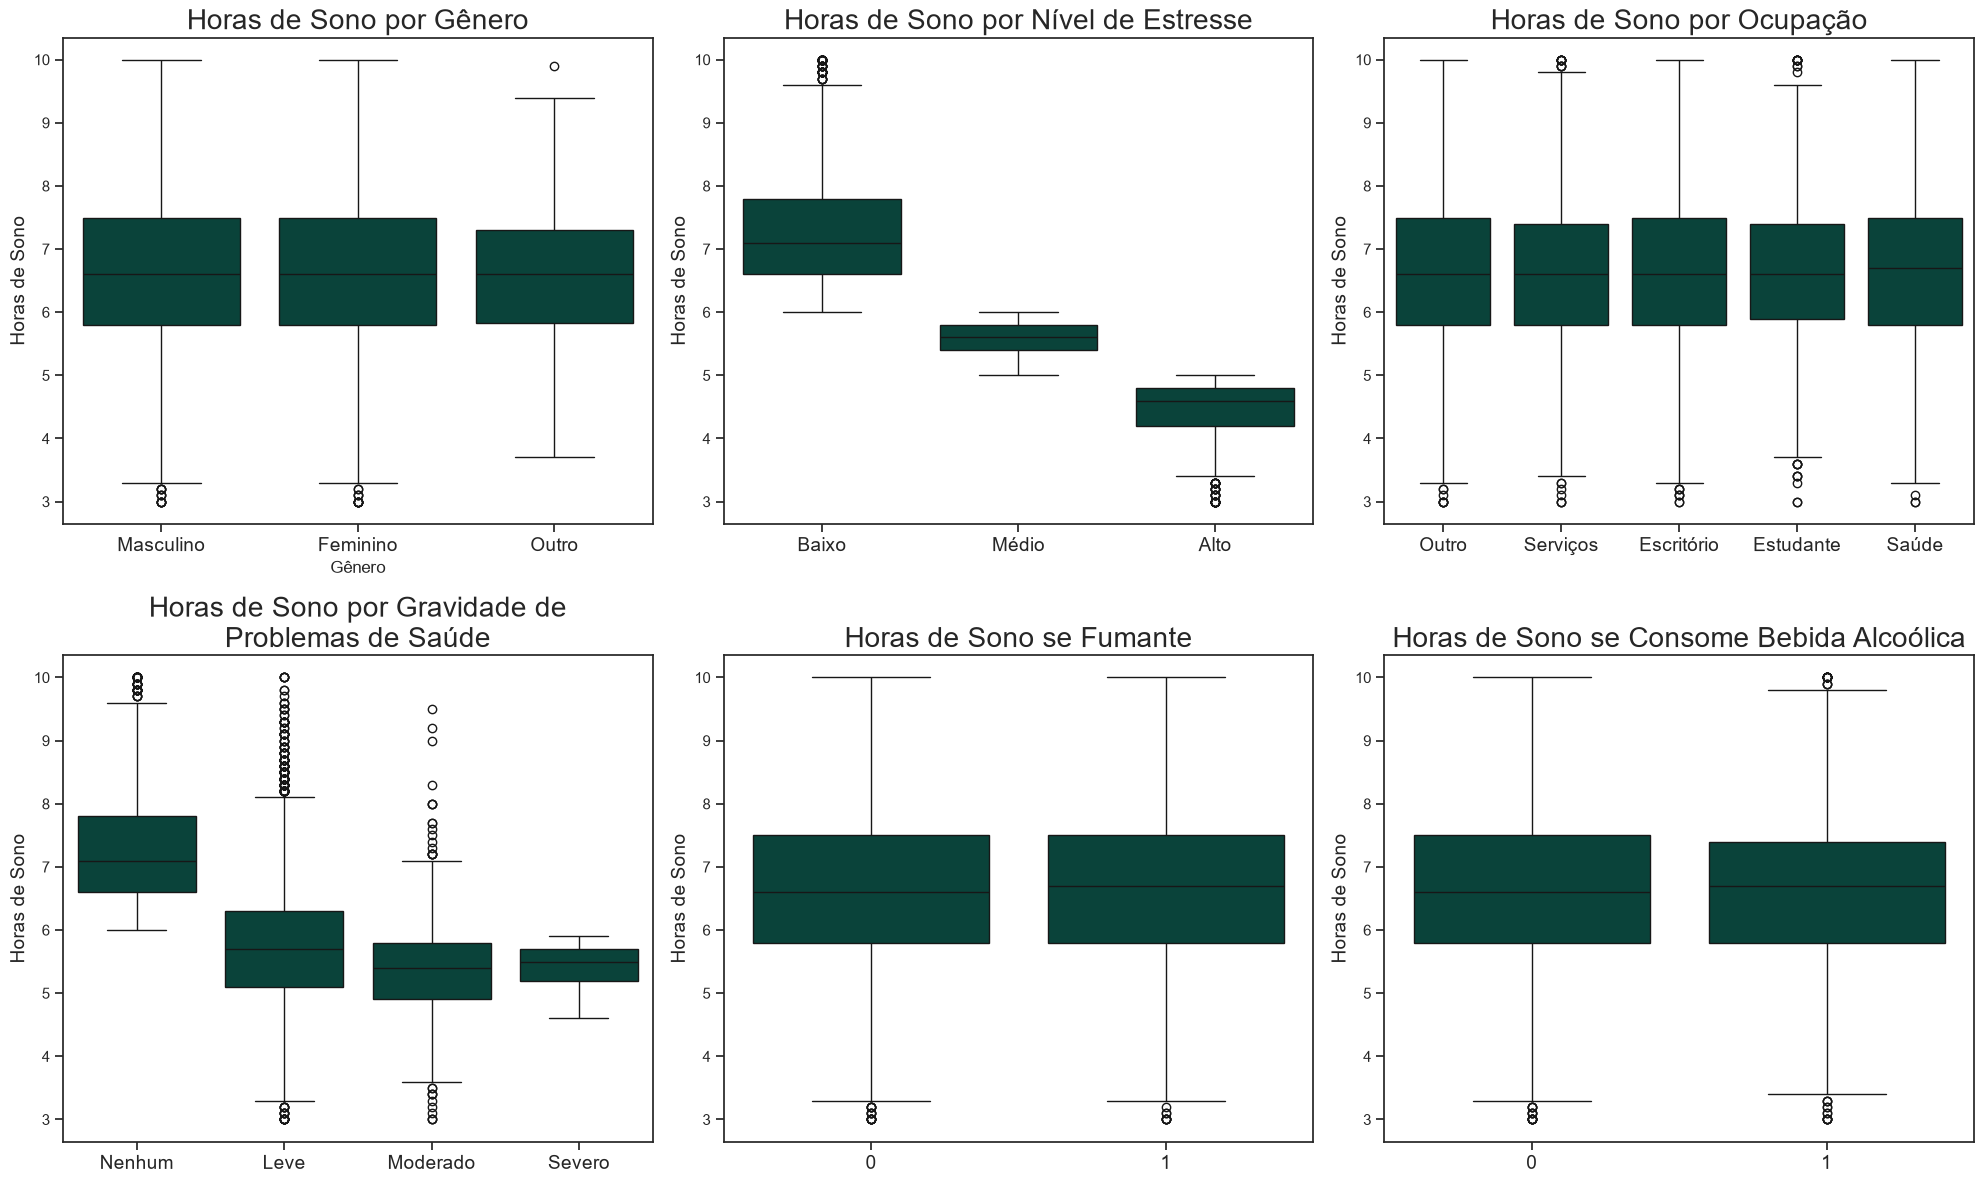

In [81]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(2, 3, figsize = (20, 12))

sns.boxplot(data = df, y = 'Horas_de_sono', x = 'Gênero', ax = ax[0,0], color = colors['green'])
ax[0,0].set_title('Horas de Sono por Gênero', fontsize = 20)
ax[0,0].set_ylabel('Horas de Sono', fontsize = 14)
ax[0,0].tick_params(axis = 'x', labelsize = 14)

sns.boxplot(data = df, y = 'Horas_de_sono', x = 'Nível_de_estresse', ax = ax[0,1], color = colors['green'])
ax[0,1].set_title('Horas de Sono por Nível de Estresse', fontsize = 20)
ax[0,1].set_ylabel('Horas de Sono', fontsize = 14)
ax[0,1].tick_params(axis = 'x', labelsize = 14)
ax[0,1].set_xlabel('')

sns.boxplot(data = df, y = 'Horas_de_sono', x = 'Ocupação', ax = ax[0,2], color = colors['green'])
ax[0,2].set_title('Horas de Sono por Ocupação', fontsize = 20)
ax[0,2].set_ylabel('Horas de Sono', fontsize = 14)
ax[0,2].tick_params(axis = 'x', labelsize = 14)
ax[0,2].set_xlabel('')

sns.boxplot(data = df, y = 'Horas_de_sono', x = 'Problemas_de_saúde', ax = ax[1,0], color = colors['green'])
ax[1,0].set_title('Horas de Sono por Gravidade de\nProblemas de Saúde', fontsize = 20)
ax[1,0].set_ylabel('Horas de Sono', fontsize = 14)
ax[1,0].tick_params(axis = 'x', labelsize = 14)
ax[1,0].set_xlabel('')

sns.boxplot(data = df, y = 'Horas_de_sono', x = 'Fumante', ax = ax[1,1], color = colors['green'])
ax[1,1].set_title('Horas de Sono se Fumante', fontsize = 20)
ax[1,1].set_ylabel('Horas de Sono', fontsize = 14)
ax[1,1].tick_params(axis = 'x', labelsize = 14)
ax[1,1].set_xlabel('')

sns.boxplot(data = df, y = 'Horas_de_sono', x = 'Consumo_de_álcool', ax = ax[1,2], color = colors['green'])
ax[1,2].set_title('Horas de Sono se Consome Bebida Alcoólica', fontsize = 20)
ax[1,2].set_ylabel('Horas de Sono', fontsize = 14)
ax[1,2].tick_params(axis = 'x', labelsize = 14)
ax[1,2].set_xlabel('')

plt.tight_layout()
plt.show()

O conjunto de dados não parece apresentar correlações entre horas de sono com gênero, ocupação, fumo ou consumo de bebidas alcoólicas. No entanto, o número de horas dormidas cai conforme o nível de estresse e gravidade dos problemas de saúde aumenta.

Como vimos anteriormente, umas das formas de uma variável descritiva afetar uma variável descrita pode se dar <b>através</b> de uma segunda variável descritiva. A seguir, iremos investigar se alguns hábitos podem elevar o nível de estresse ou agravar a saúde dos clientes selecionados na camostra.

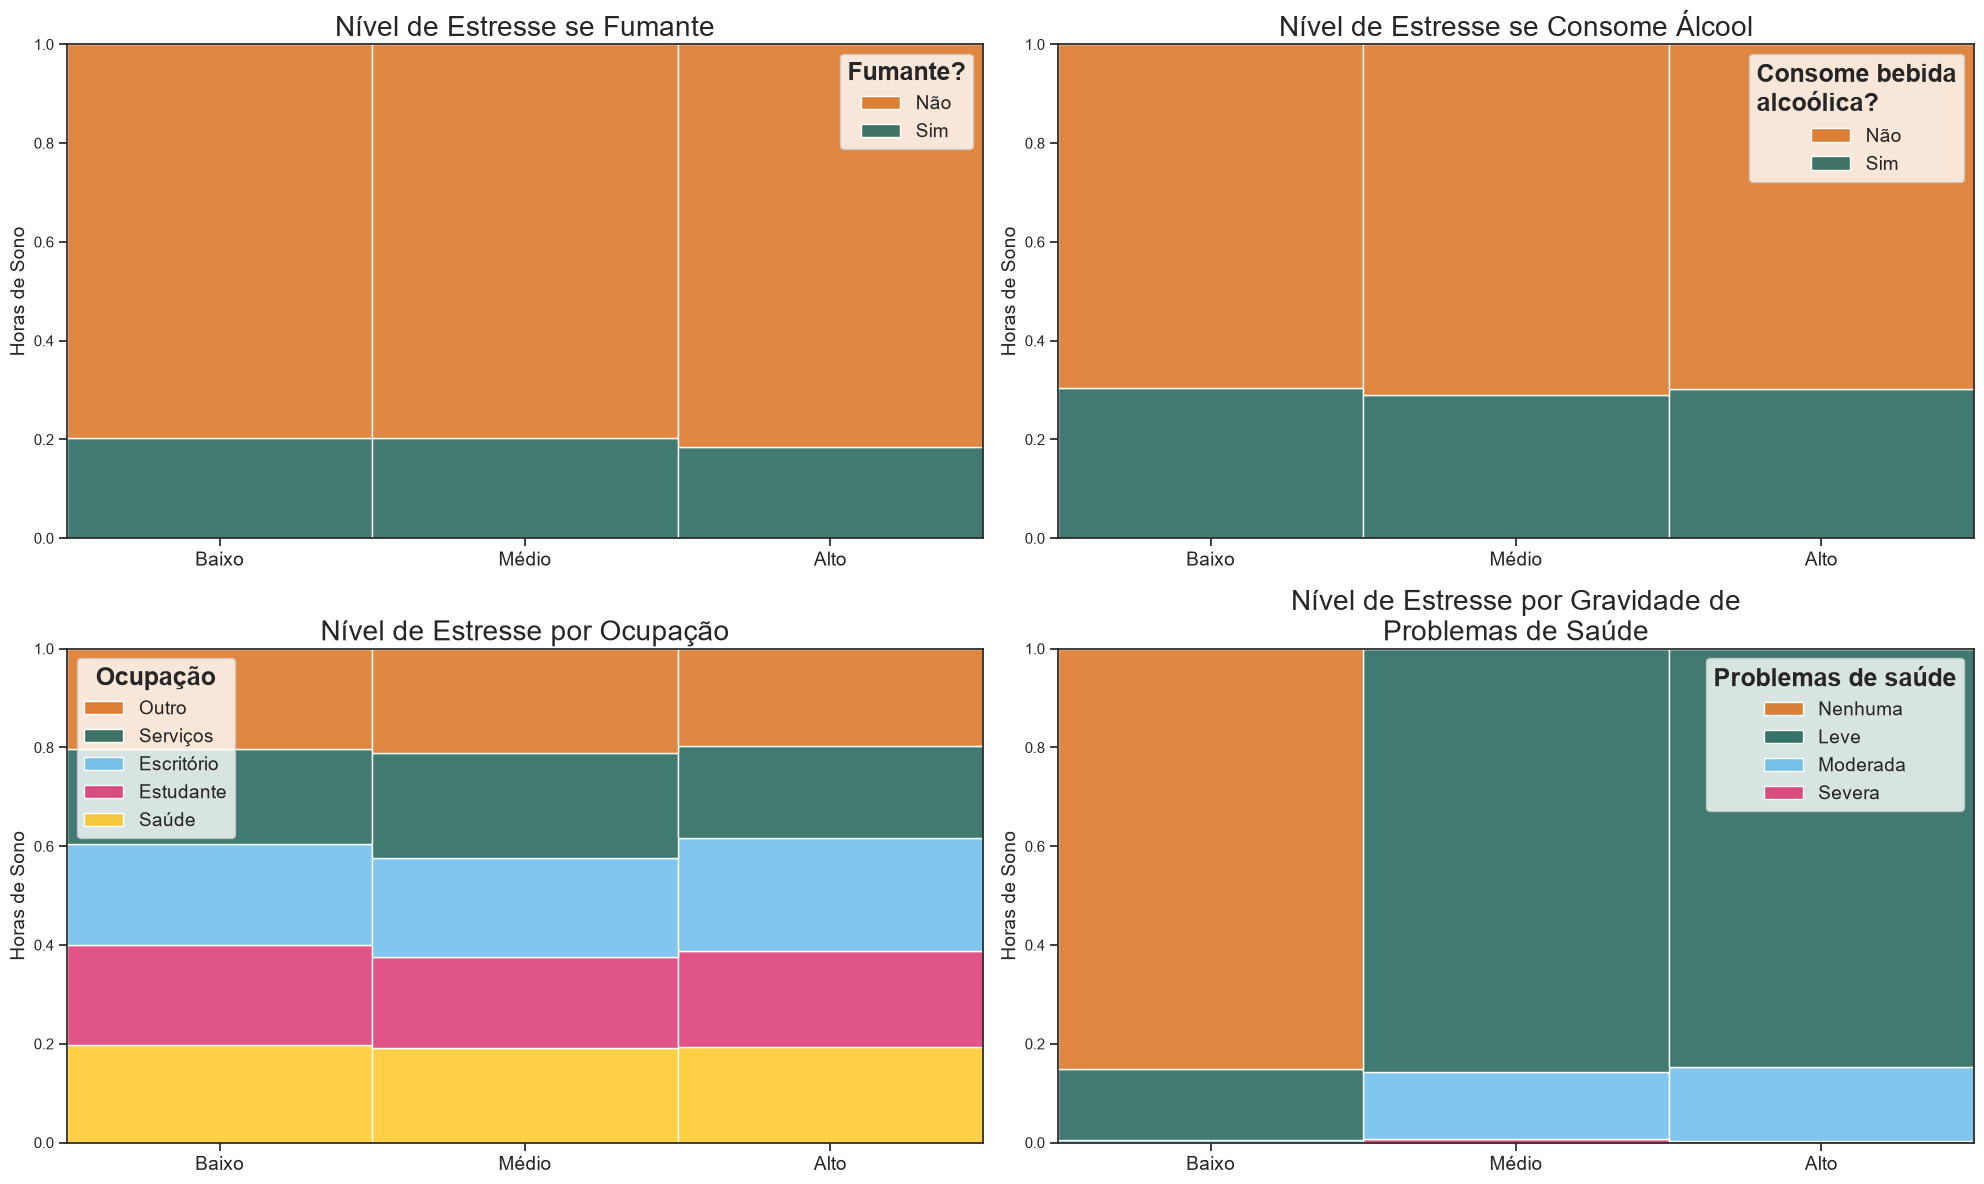

In [82]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(2, 2, figsize = (20, 12))

sns.histplot(data = df, x = 'Nível_de_estresse', hue = 'Fumante', ax = ax[0,0], stat = 'proportion', palette=[colors['orange'], colors['green']],
            multiple = 'fill')
ax[0,0].set_title('Nível de Estresse se Fumante', fontsize = 20)
ax[0,0].set_ylabel('Horas de Sono', fontsize = 14)
ax[0,0].tick_params(axis = 'x', labelsize = 14)
ax[0,0].set_xlabel('')
ax[0,0].legend(labels = ['Sim', 'Não'], fontsize = 14, title = 'Fumante?', title_fontproperties = {'size':18, 'weight': 'bold'}, reverse = True)

sns.histplot(data = df, x = 'Nível_de_estresse', hue = 'Consumo_de_álcool', ax = ax[0,1], stat = 'proportion', 
             palette=[colors['orange'], colors['green']],
            multiple = 'fill')
ax[0,1].set_title('Nível de Estresse se Consome Álcool', fontsize = 20)
ax[0,1].set_ylabel('Horas de Sono', fontsize = 14)
ax[0,1].tick_params(axis = 'x', labelsize = 14)
ax[0,1].set_xlabel('')
ax[0,1].legend(labels = ['Sim', 'Não'], fontsize = 14, title = 'Consome bebida\nalcoólica?', title_fontproperties = {'size':18, 'weight': 'bold'},
               reverse = True)

sns.histplot(data = df, x = 'Nível_de_estresse', hue = 'Ocupação', ax = ax[1,0], stat = 'proportion', 
              palette=[colors['orange'], colors['green'],colors['blue'], colors['magenta'],colors['yellow']],
            multiple = 'fill')
ax[1,0].set_title('Nível de Estresse por Ocupação', fontsize = 20)
ax[1,0].set_ylabel('Horas de Sono', fontsize = 14)
ax[1,0].tick_params(axis = 'x', labelsize = 14)
ax[1,0].set_xlabel('')
ax[1,0].legend(labels = ['Saúde', 'Estudante', 'Escritório', 'Serviços', 'Outro'], 
               fontsize = 14, title = 'Ocupação', title_fontproperties = {'size':18, 'weight': 'bold'},
               reverse = True)

sns.histplot(data = df, x = 'Nível_de_estresse', hue = 'Problemas_de_saúde', ax = ax[1,1], stat = 'proportion', 
              palette=[colors['orange'], colors['green'],colors['blue'], colors['magenta']],
            multiple = 'fill')
ax[1,1].set_title('Nível de Estresse por Gravidade de\nProblemas de Saúde', fontsize = 20)
ax[1,1].set_ylabel('Horas de Sono', fontsize = 14)
ax[1,1].tick_params(axis = 'x', labelsize = 14)
ax[1,1].set_xlabel('')
ax[1,1].legend(labels = ['Severa', 'Moderada', 'Leve', 'Nenhuma'], 
               fontsize = 14, title = 'Problemas de saúde', title_fontproperties = {'size':18, 'weight': 'bold'},
               reverse = True)

plt.tight_layout()
plt.show()

A única falta de propoção constatada entre os gráficos explorando o nível de estresse dos clientes do banco de dados está nos problemas de saúde. Pessoas com problemas de saúde leves a moderados apresetam um nível de estresse maior e, portanto, provavelmente dormem pior que os clientes sem problemas de saúde.

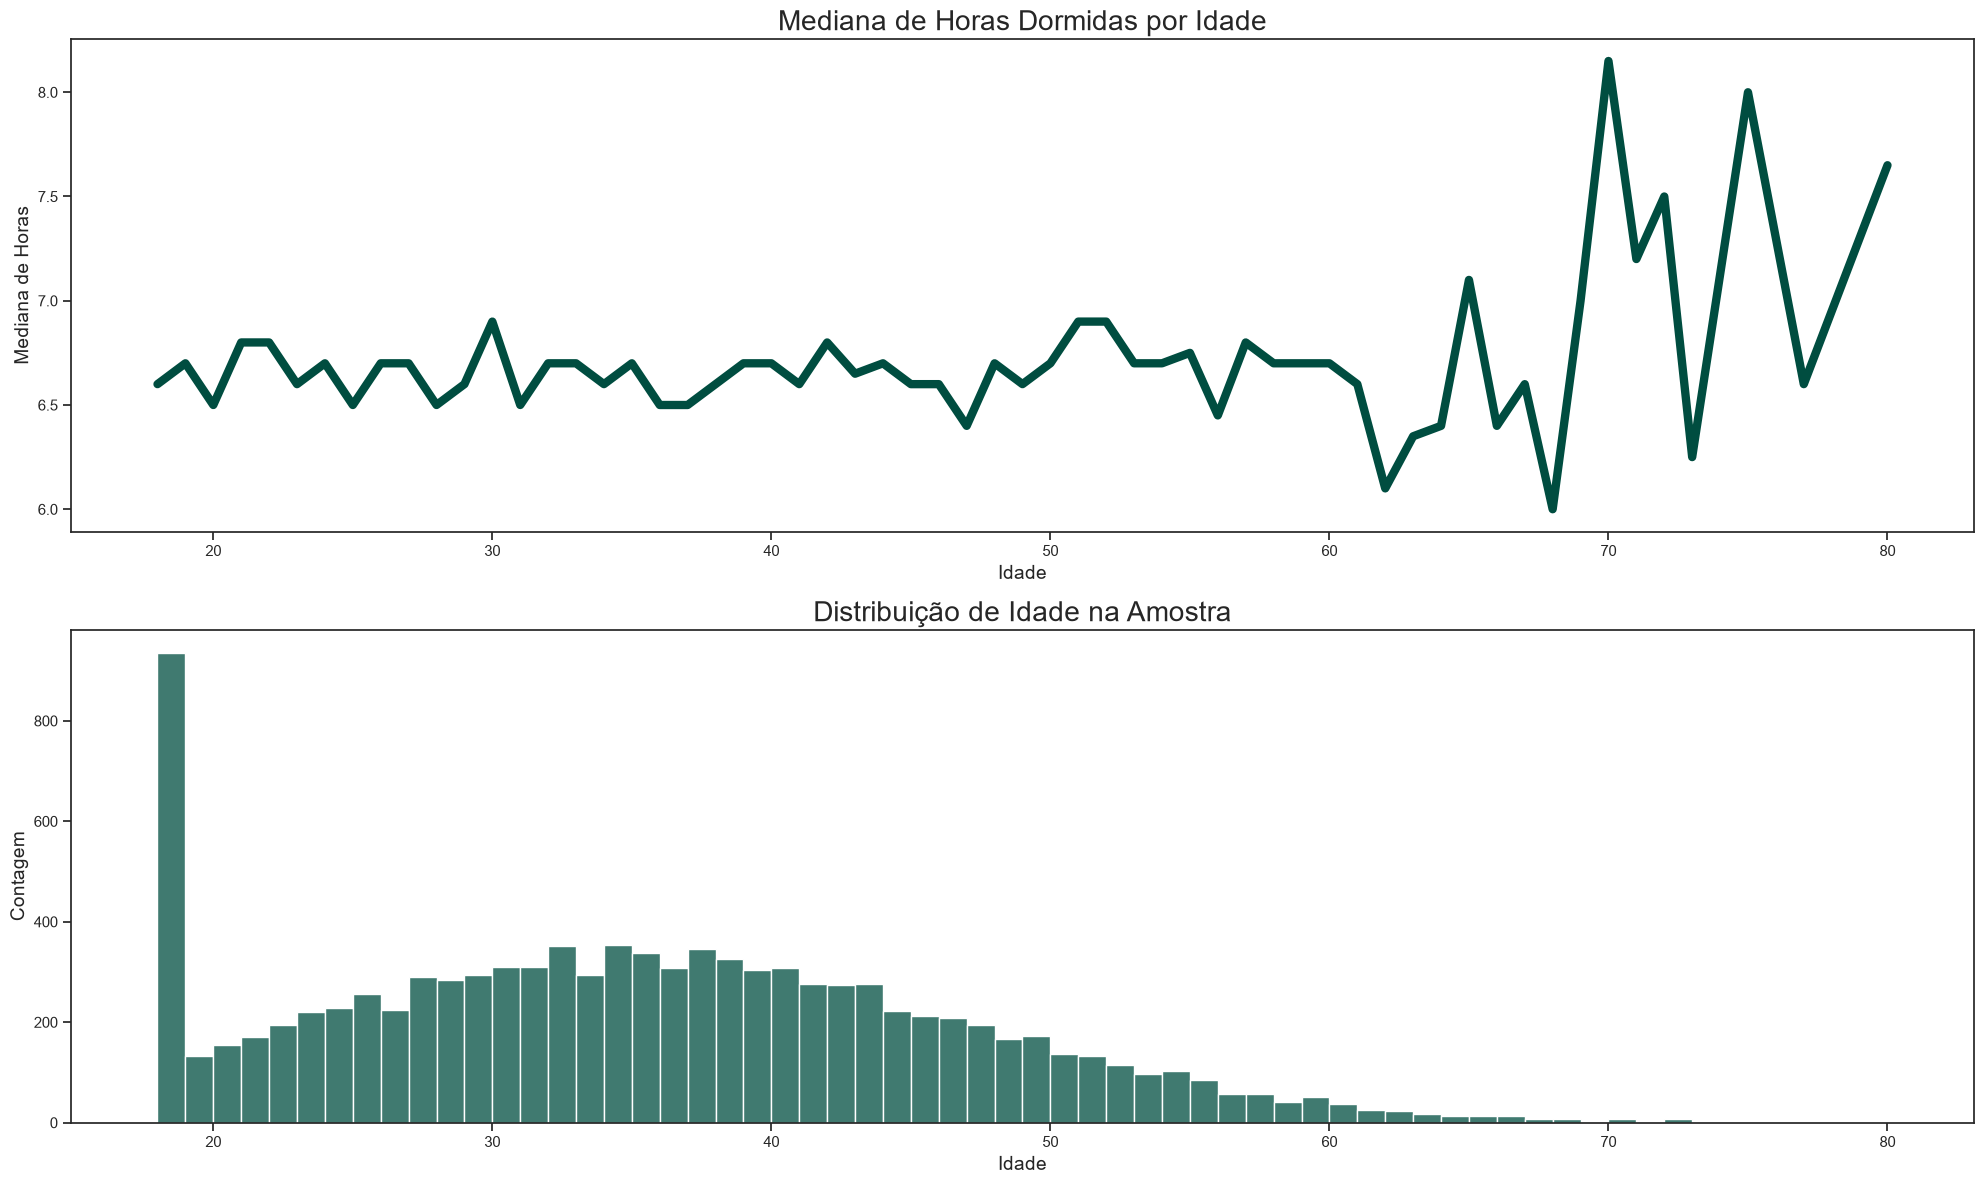

In [83]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(2,1, figsize = (20, 12))

sns.lineplot(data = df, y = 'Horas_de_sono', x = 'Idade', color = colors['green'], ax = ax[0],
            estimator = 'median', errorbar = None, linewidth = 6)
ax[0].set_title('Mediana de Horas Dormidas por Idade', fontsize = 20)
ax[0].set_ylabel('Mediana de Horas', fontsize = 14)
ax[0].set_xlabel('Idade', fontsize = 14)

sns.histplot(data = df, x = 'Idade', color = colors['green'], ax = ax[1], binwidth = 1)
ax[1].set_title('Distribuição de Idade na Amostra', fontsize = 20)
ax[1].set_ylabel('Contagem', fontsize = 14)
ax[1].set_xlabel('Idade', fontsize = 14)

plt.tight_layout()
plt.show()

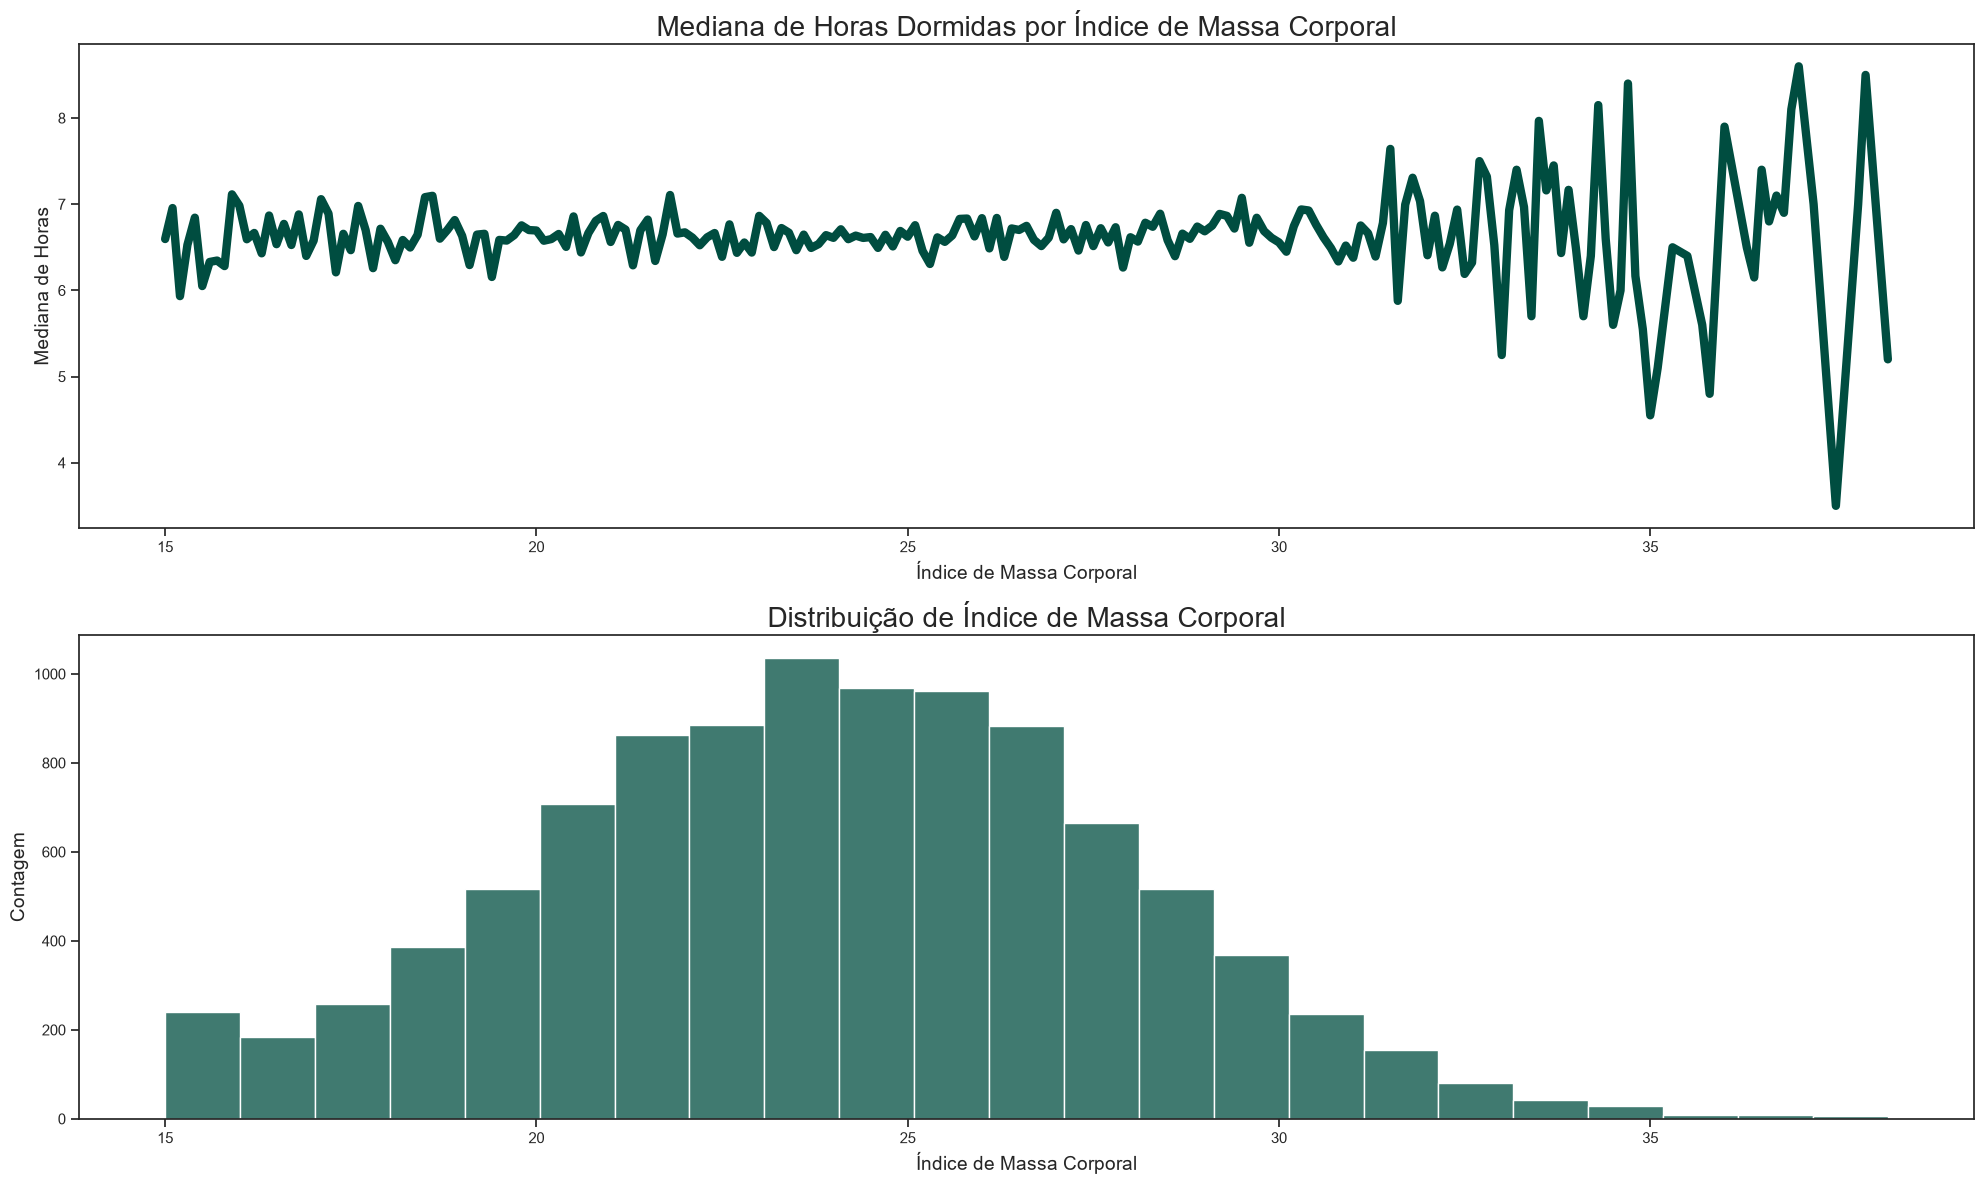

In [84]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(2,1, figsize = (20, 12))

sns.lineplot(data = df, y = 'Horas_de_sono', x = 'IMC', color = colors['green'], ax = ax[0],
            estimator = 'average', errorbar = None, linewidth = 6)
ax[0].set_title('Mediana de Horas Dormidas por Índice de Massa Corporal', fontsize = 20)
ax[0].set_ylabel('Mediana de Horas', fontsize = 14)
ax[0].set_xlabel('Índice de Massa Corporal', fontsize = 14)

sns.histplot(data = df, x = 'IMC', color = colors['green'], ax = ax[1], binwidth = 1)
ax[1].set_title('Distribuição de Índice de Massa Corporal', fontsize = 20)
ax[1].set_ylabel('Contagem', fontsize = 14)
ax[1].set_xlabel('Índice de Massa Corporal', fontsize = 14)

plt.tight_layout()
plt.show()

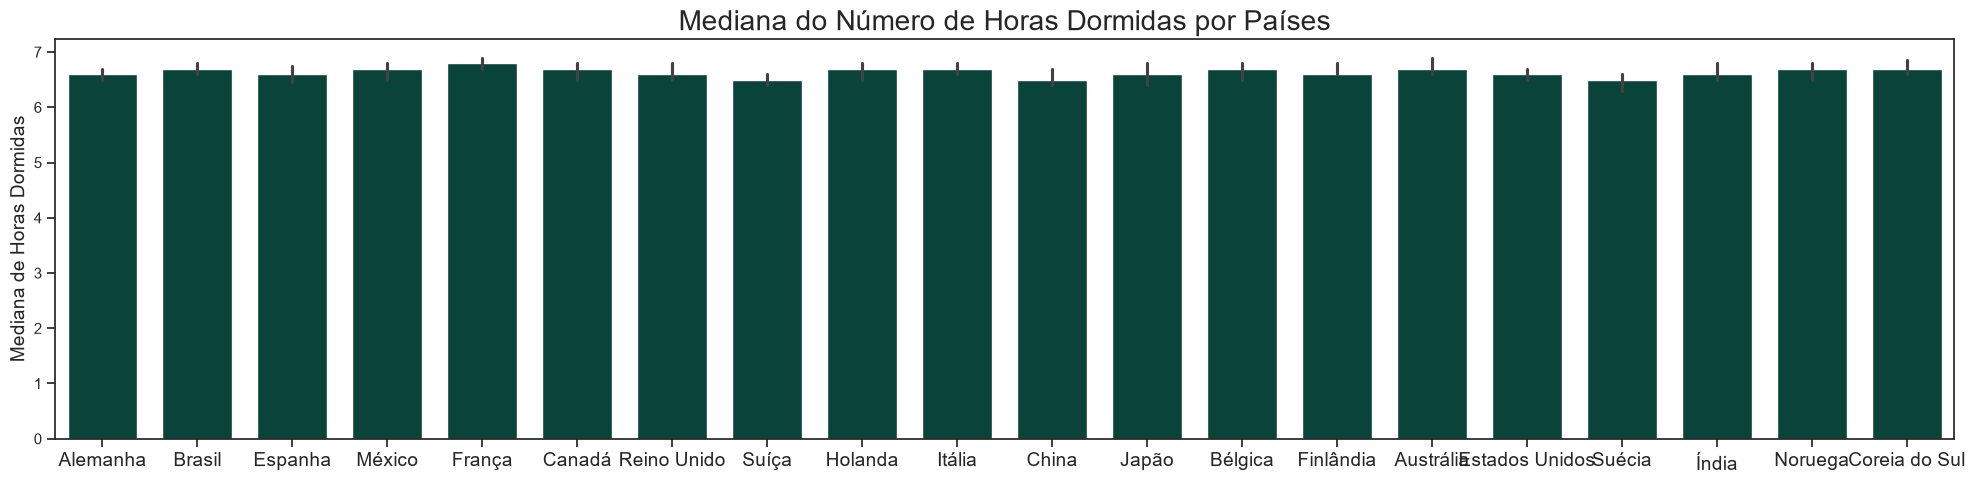

In [85]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(figsize = (20, 5))

sns.barplot(data = df, y = 'Horas_de_sono', x = 'País', color = colors['green'], estimator = 'median', gap = 0.08)
ax.set_title('Mediana do Número de Horas Dormidas por Países', fontsize = 20)
ax.set_ylabel('Mediana de Horas Dormidas', fontsize = 14)
ax.tick_params(axis = 'x', labelsize = 14)
ax.set_xlabel('')

plt.tight_layout()
plt.show()

Avaliando a mediana de horas dormidas por idade, também não é possível constatar uma tendência de melhora ou piora conforme as pessoas envelhecem.  partir de determinado ponto, o gráfico fica mais volátil por conta do número de observações ser muitíssimo inferior nesta porção.

A mesma constatação pode ser feita para o IMC. Não é possível afirmar, com base nos dados fornecidos, que mudanças no IMC alteram substancialmente a qualidade do sono. A mesma observação pode ser feita para a volatilidade ao final do gráfico.

Também não existem distinções na qualidade do sono dos clientes residentes em países distintos.

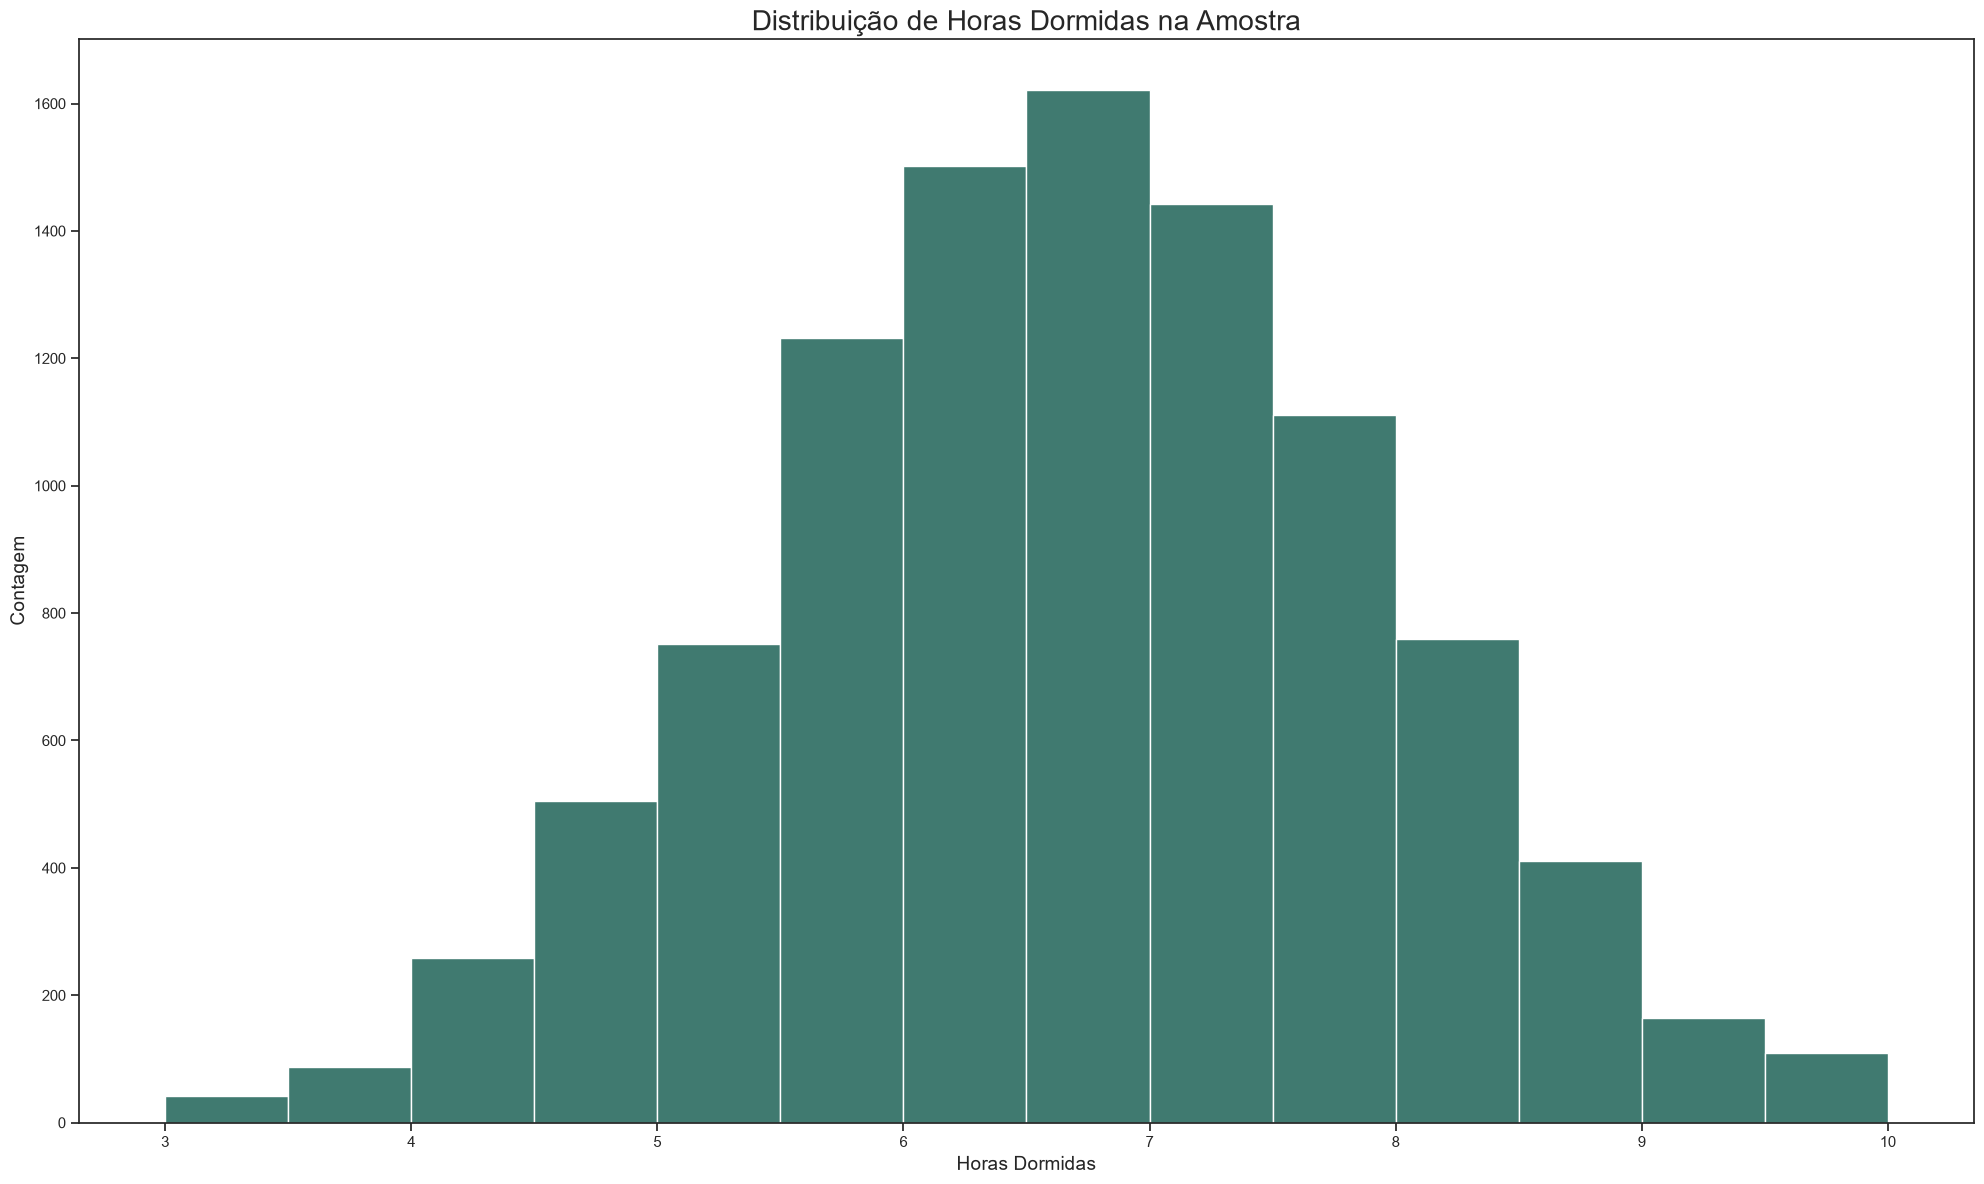

In [86]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(figsize = (20, 12))

sns.histplot(data = df, x = 'Horas_de_sono', color = colors['green'], binwidth = 0.5)
ax.set_title('Distribuição de Horas Dormidas na Amostra', fontsize = 20)
ax.set_ylabel('Contagem', fontsize = 14)
ax.set_xlabel('Horas Dormidas', fontsize = 14)

plt.tight_layout()
plt.show()

A distribuição do número de horas dormidas na amostra é simétrica. Para atestar a normalidade, o dieal seria realizar testes, como o Shapiro-Wilk, ou avaliando a assimetria e curtose da distribuição.

<h2>Primeiros insights</h2>

A maior parte do dataset possui correlação muito próxima a 0 com a variavel de interesse. As exceções são "Ingestão_de_café" e "Cafeína_mg" (sendo que são perfeitamente correlacionadas, já que uma xícara de café equivale a aproximadamente 95mg de cafeína, de acordo com o dicionário de dados) e a "Frequência_cardíaca". 

"Nível_de_estresse" também será incluída por, através da análise do DAG, ser uma variável que não consegue afetar a variável de interesse através de outras variáveis, como "Idade" consegue afetar a qualidade do sono através de "Frequência_cardíaca" por exemplo.

https://mixtape.scunning.com/03-directed_acyclical_graphs

Ao analisar os <i>boxplots</i>, é possível notar uma correlação entre ingestão de cafeína com piora na qualidade do sono, aumento do estresse e aumento de problemas de saúde, embora problemas de saúde severos possam conter outras causas além da ingestão de cafeína, já que nessa categoria o comportamento está truncado. Vale relembrar que o <i>feedback</i> positivo entre nível de estresse e consumo de café será assumida como constante ao longo do tempo e desconsiderada do modelo. Não existe uma tendência aparente de aumento ou redução de consumo de cafeína quando analisamos gênero ou ocupação.

A quantidade de horas dormidas também parece afetar o nível de estresse e problemas de saúde. Como essas seriam relações cíclicas, como o caso do café x nível de estresse e, não sendo possível desenvolver modelos baseados em dados em painel, a retroalimentação entre essas variáveis também será assumida como constante ao longo do tempo e desconsiderada do modelo.

Gênero, ocupação, idade, país de origem, consumo de cigarros e consumo de álcool não parecem afetar o modo de como as pessoas consomem café no dataset estudado.

<h2>Distribuições entre Variáveis Categóricas</h2>

Agora vamos explorar a distribuição entre variáveis categóricas para entender o balanceamento dessas variáveis.

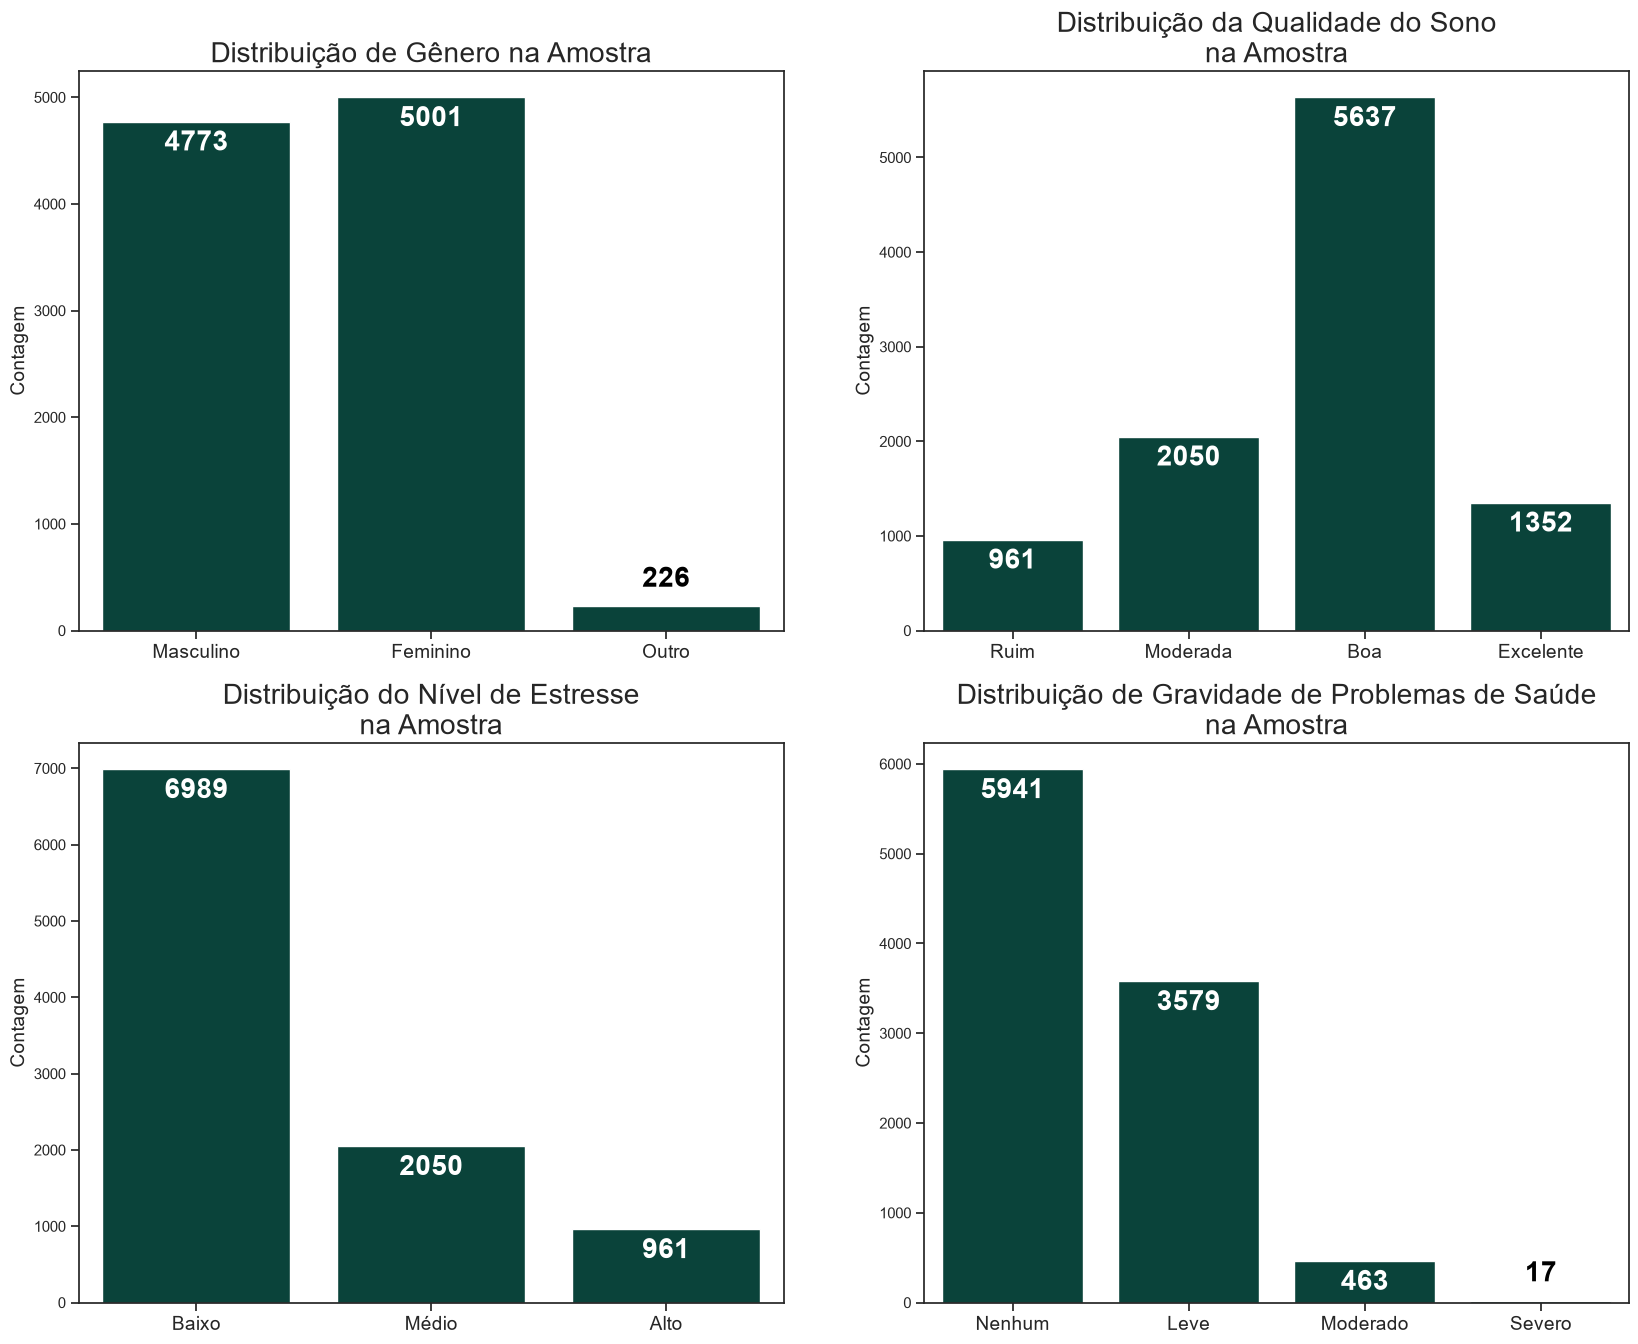

In [87]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(2, 2, figsize = (20, 16))

sns.countplot(data = df, x = 'Gênero', ax = ax[0,0], color = colors['green'])
ax[0,0].set_title('Distribuição de Gênero na Amostra', fontsize = 20)
ax[0,0].set_ylabel('Contagem', fontsize = 14)
ax[0,0].tick_params(axis = 'x', labelsize = 14)
ax[0,0].set_xlabel('')
container_00 = ax[0,0].containers[0]
label_001 = ax[0,0].bar_label(container_00, weight = 'bold', fontsize = 20)
label_001[0].set_color('white')
label_001[0].set_position((0,-25))
label_001[1].set_color('white')
label_001[1].set_position((0,-25))
label_001[2].set_color('black')
label_001[2].set_position((0,10))

sns.countplot(data = df, x = 'Qualidade_do_sono', ax = ax[0,1], color = colors['green'], order = ['Ruim', 'Moderada', 'Boa', 'Excelente'])
ax[0,1].set_title('Distribuição da Qualidade do Sono\nna Amostra', fontsize = 20)
ax[0,1].set_ylabel('Contagem', fontsize = 14)
ax[0,1].tick_params(axis = 'x', labelsize = 14)
ax[0,1].set_xlabel('')
container_01 = ax[0,1].containers[0]
ax[0,1].bar_label(container_01, padding = -25, fontsize = 20, color = 'white', weight = 'bold')

sns.countplot(data = df, x = 'Nível_de_estresse', ax = ax[1,0], color = colors['green'])
ax[1,0].set_title('Distribuição do Nível de Estresse\nna Amostra', fontsize = 20)
ax[1,0].set_ylabel('Contagem', fontsize = 14)
ax[1,0].tick_params(axis = 'x', labelsize = 14)
ax[1,0].set_xlabel('')
container_10 = ax[1,0].containers[0]
ax[1,0].bar_label(container_10, padding = -25, fontsize = 20, color = 'white', weight = 'bold')

sns.countplot(data = df, x = 'Problemas_de_saúde', ax = ax[1,1], color = colors['green'])
ax[1,1].set_title('Distribuição de Gravidade de Problemas de Saúde\nna Amostra', fontsize = 20)
ax[1,1].set_ylabel('Contagem', fontsize = 14)
ax[1,1].tick_params(axis = 'x', labelsize = 14)
ax[1,1].set_xlabel('')
container_11 = ax[1,1].containers[0]
labels_11 = ax[1,1].bar_label(container_11, padding = -25, fontsize = 20, color = 'white', weight = 'bold')
labels_11[3].set_color('black')
labels_11[3].set_position((0,10))

plt.show()

Todas as variáveis categóricas de interesse estão desbalanceadas. Teremos que tratar o problema, já que os modelos mais comuns acabam tendo problemas em lidar com classes desbalanceadas. Alternativas que poderão ser usadas incluem <b>SMOTE</b> ou <i>Class Weights</i>.

<h1>Pré-processamento dos dados</h1>

In [88]:
colunas = df.columns
colunas

Index(['ID', 'Idade', 'Gênero', 'País', 'Ingestão_de_café', 'Cafeína_mg',
       'Horas_de_sono', 'Qualidade_do_sono', 'IMC', 'Frequência_cardíaca',
       'Nível_de_estresse', 'Atividade_física', 'Problemas_de_saúde',
       'Ocupação', 'Fumante', 'Consumo_de_álcool'],
      dtype='object')

In [95]:
#dfModelo = df[['Ingestão_de_café', 'Qualidade_do_sono', 'Idade', 'Frequência_cardíaca', 'Nível_de_estresse',
#       'Atividade_física', 'Problemas_de_saúde']]
#dfModelo.head(10)

dfModelo = df[['Ingestão_de_café', 'Qualidade_do_sono', 'Frequência_cardíaca', 'Nível_de_estresse']]
dfModelo.head(10)

,Ingestão_de_café,Qualidade_do_sono,Frequência_cardíaca,Nível_de_estresse
0,3.5,Boa,78,Baixo
1,1.0,Boa,67,Baixo
2,5.3,Moderada,59,Médio
3,2.6,Boa,71,Baixo
4,3.1,Moderada,76,Médio
5,3.4,Boa,82,Baixo
6,2.7,Boa,58,Baixo
7,4.5,Moderada,62,Médio
8,1.7,Boa,60,Baixo
9,4.0,Boa,69,Baixo


In [96]:
dfModelo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Ingestão_de_café     10000 non-null  float64
 1   Qualidade_do_sono    10000 non-null  object 
 2   Frequência_cardíaca  10000 non-null  int64  
 3   Nível_de_estresse    10000 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 312.6+ KB


In [97]:
dfBkp = dfModelo.copy()
dfBkp.head(10)

,Ingestão_de_café,Qualidade_do_sono,Frequência_cardíaca,Nível_de_estresse
0,3.5,Boa,78,Baixo
1,1.0,Boa,67,Baixo
2,5.3,Moderada,59,Médio
3,2.6,Boa,71,Baixo
4,3.1,Moderada,76,Médio
5,3.4,Boa,82,Baixo
6,2.7,Boa,58,Baixo
7,4.5,Moderada,62,Médio
8,1.7,Boa,60,Baixo
9,4.0,Boa,69,Baixo


<h2>Usando o OrdinalEncoder do scikit-learn</h2>

<p>Antes de alimentar os algoritmos de machine learning, precisamos codificar as variáveis categóricas presentes no conjunto de dados. Para essa tarefa, a ferramenta escolhida foi o <i>OrdinalEncoder</i>.</p>

<p>O OrdinalEncoder, presente na biblioteca scikit-learn, será fundamental neste projeto porque todas as nossas variáveis categóricas focais (qualidade do sono, nível de estresse e problemas de saúde) possuem um ordenamento lógico implícito (ex: de "Ruim" para "Excelente").</p>

<p>Além disso, como veremos mais à frente, manter essa hierarquia nos permitirá utilizar modelos específicos que consideram a distância entre as categorias no momento de realizar a classificação. Nesses modelos, a penalização matemática é significativamente maior quando a previsão passa muito longe do rótulo verdadeiro (por exemplo, classificar como "Excelente" um sono que na verdade era "Ruim"), algo que modelos padrão não compreendem naturalmente.</p>

In [98]:
#qualidadeSono = ['Ruim', 'Moderada', 'Boa', 'Excelente']
#nivelEstresse = ['Baixo', 'Médio', 'Alto']
#problemasSaude = ['Nenhum', 'Leve', 'Moderado', 'Severo']
#
#toEncode = [qualidadeSono, nivelEstresse, problemasSaude]
#
#encoder = OrdinalEncoder(categories = toEncode)
#encodedArray = encoder.fit_transform(dfModelo[['Qualidade_do_sono', 'Nível_de_estresse', 'Problemas_de_saúde']])
#
#colNames = ['E_Qualidade_do_sono', 'E_Nivel_de_estresse', 'E_Problemas_de_saúde']
#encodedArray = pd.DataFrame(encodedArray, columns = colNames)


qualidadeSono = ['Ruim', 'Moderada', 'Boa', 'Excelente']
nivelEstresse = ['Baixo', 'Médio', 'Alto']

toEncode = [qualidadeSono, nivelEstresse]

encoder = OrdinalEncoder(categories = toEncode)
encodedArray = encoder.fit_transform(dfModelo[['Qualidade_do_sono', 'Nível_de_estresse']])

colNames = ['E_Qualidade_do_sono', 'E_Nivel_de_estresse']
encodedArray = pd.DataFrame(encodedArray, columns = colNames)

In [99]:
dfModelo = dfModelo.merge(encodedArray, on = dfModelo.index)

dfModelo

,key_0,Ingestão_de_café,Qualidade_do_sono,Frequência_cardíaca,Nível_de_estresse,E_Qualidade_do_sono,E_Nivel_de_estresse
0,0,3.5,Boa,78,Baixo,2.0,0.0
1,1,1.0,Boa,67,Baixo,2.0,0.0
2,2,5.3,Moderada,59,Médio,1.0,1.0
3,3,2.6,Boa,71,Baixo,2.0,0.0
4,4,3.1,Moderada,76,Médio,1.0,1.0
...,...,...,...,...,...,...,...
9995,9995,2.1,Moderada,50,Médio,1.0,1.0
9996,9996,3.4,Moderada,71,Médio,1.0,1.0
9997,9997,1.6,Boa,66,Baixo,2.0,0.0
9998,9998,3.4,Boa,80,Baixo,2.0,0.0


In [103]:
#dfModelo = dfModelo[['Ingestão_de_café', 'Idade', 'Frequência_cardíaca', 'Atividade_física', 'E_Qualidade_do_sono', 'E_Nivel_de_estresse', 'E_Problemas_de_saúde']]

dfModelo = dfModelo[['Ingestão_de_café', 'Frequência_cardíaca', 'E_Qualidade_do_sono', 'E_Nivel_de_estresse']]
dfModelo

,Ingestão_de_café,Frequência_cardíaca,E_Qualidade_do_sono,E_Nivel_de_estresse
0,3.5,78,2.0,0.0
1,1.0,67,2.0,0.0
2,5.3,59,1.0,1.0
3,2.6,71,2.0,0.0
4,3.1,76,1.0,1.0
...,...,...,...,...
9995,2.1,50,1.0,1.0
9996,3.4,71,1.0,1.0
9997,1.6,66,2.0,0.0
9998,3.4,80,2.0,0.0


<h2>Dividindo o Conjunto Entre Treino e Teste e Balanceando as Amostras de Teste</h2>



In [104]:
X = dfModelo.drop('E_Qualidade_do_sono', axis = 1)
y = dfModelo[['E_Qualidade_do_sono']]
xTreino, xTeste, yTreino, yTeste = train_test_split(X, y, stratify = y, test_size = 0.2, random_state = 60494)

In [105]:
print('Train/ Test shapes: \n\n'
    f"x_train: {xTreino.shape}\nx_test: {xTeste.shape}\ny_train: {yTreino.shape}\ny_test: {yTeste.shape}"
)

Train/ Test shapes: 

x_train: (8000, 3)
x_test: (2000, 3)
y_train: (8000, 1)
y_test: (2000, 1)


In [106]:
#smote = SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse', 'E_Problemas_de_saúde']) ##Passar apenas da matrix X
#xTreinoSM, yTreinoSM = smote.fit_resample(xTreino, yTreino)
#
#print('Train/ Test shapes: \n\n'
#    f"x_train: {xTreinoSM.shape}\ny_train: {yTreinoSM.shape}"
#)

smote = SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse']) ##Passar apenas da matrix X
xTreinoSM, yTreinoSM = smote.fit_resample(xTreino, yTreino)

print('Train/ Test shapes: \n\n'
    f"x_train: {xTreinoSM.shape}\ny_train: {yTreinoSM.shape}"
)

Train/ Test shapes: 

x_train: (18036, 3)
y_train: (18036, 1)


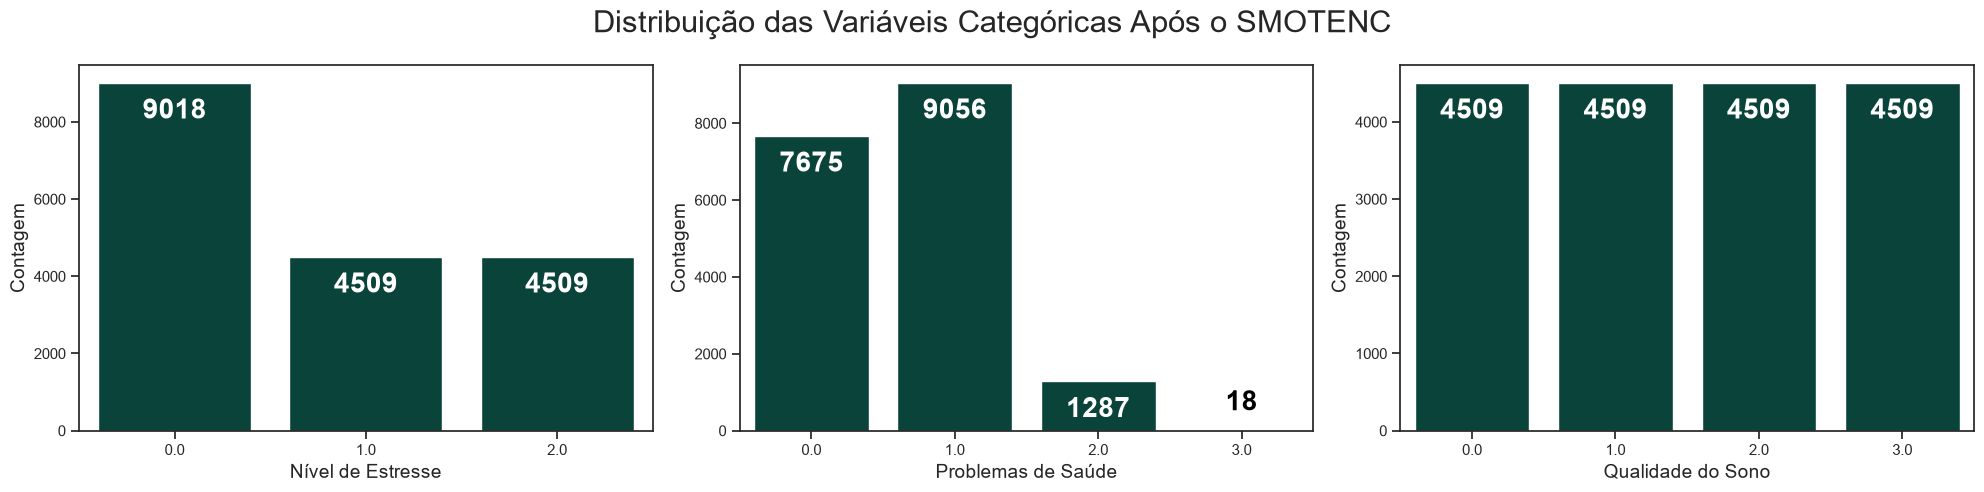

In [34]:
sns.set_theme(style = 'ticks', palette = 'pastel')

fig, ax = plt.subplots(1, 3, figsize = (20, 5))

plt.suptitle('Distribuição das Variáveis Categóricas Após o SMOTENC', fontsize = 22)

sns.countplot(data = xTreinoSM, x = 'E_Nivel_de_estresse', ax = ax[0], color = colors['green'])

ax[0].set_ylabel('Contagem', fontsize = 14)
ax[0].set_xlabel('Nível de Estresse', fontsize = 14)
container_0 = ax[0].containers[0]
ax[0].bar_label(container_0, padding = -30, color = 'white', fontsize = 20, weight = 'bold')

sns.countplot(data = xTreinoSM, x = 'E_Problemas_de_saúde', ax = ax[1], color = colors['green'])
ax[1].set_ylabel('Contagem', fontsize = 14)
ax[1].set_xlabel('Problemas de Saúde', fontsize = 14)
container_1 = ax[1].containers[0]
labels_1 = ax[1].bar_label(container_1, padding = -30, color = 'white', fontsize = 20, weight = 'bold')
labels_1[3].set_color('black')
labels_1[3].set_position((0,10))

sns.countplot(data = yTreinoSM, x = 'E_Qualidade_do_sono', ax = ax[2], color = colors['green'])
ax[2].set_ylabel('Contagem', fontsize = 14)
ax[2].set_xlabel('Qualidade do Sono', fontsize = 14)
container_2 = ax[2].containers[0]
ax[2].bar_label(container_2, padding = -30, color = 'white', fontsize = 20, weight = 'bold')

plt.tight_layout()
plt.show()

In [107]:
xTreinoSM.columns

Index(['Ingestão_de_café', 'Frequência_cardíaca', 'E_Nivel_de_estresse'], dtype='object')

In [108]:
yTreinoSM.columns

Index(['E_Qualidade_do_sono'], dtype='object')

<h1>Pradonização dos Dados usando o StandardScaler do sci-kit learn</h1>

Alguns modelos possuem como base o cálculo da distância entre pontos durante a realização da classificação. Nesses casos, diferenças na ordem de grandeza entre as variáveis podem acabar gerando viés de escala, onde uma variável acaba ganhando mais importância no modelo não porque ela realmente é mais importante, mas por ter um <i>range</i> de valores maior que as outras variáveis.

O StandardScaler é uma função que força que todas as distribuições do conjunto de dados tenha média zero e desvio padrão igual a um, convertendo todas as variáveis para uma mesma escala universal. Note que as variáveis <i>dummies</i> não podem ser padronizadas, já que são produto de uma codificação feita previamente para que as variáveis qualitativas presentes no conjunto de dados possam ser processadas pelos modelos.

In [109]:
#cols = ['Ingestão_de_café', 'Idade', 'Atividade_física', 'Frequência_cardíaca']
#ct = ColumnTransformer(transformers = [('scaler', StandardScaler(copy = False), cols)], remainder = 'passthrough')
#ct.set_output(transform = 'pandas')
#
#xTreinoScaled = ct.fit_transform(xTreinoSM)
#
#rename_dict = {
#    'scaler__Ingestão_de_café': 'Ingestão_de_café', 'scaler__Idade': 'Idade', 'scaler__Frequência_cardíaca': 'Frequência_cardíaca', 
#    'scaler__Atividade_física': 'Atividade_física', 'remainder__E_Nivel_de_estresse': 'E_Nivel_de_estresse', 
#    'remainder__E_Problemas_de_saúde': 'E_Problemas_de_saúde'
#}
#xTreinoScaled.rename(columns=rename_dict, inplace=True)



cols = ['Ingestão_de_café', 'Frequência_cardíaca']
ct = ColumnTransformer(transformers = [('scaler', StandardScaler(copy = False), cols)], remainder = 'passthrough')
ct.set_output(transform = 'pandas')

xTreinoScaled = ct.fit_transform(xTreinoSM)

rename_dict = {
    'scaler__Ingestão_de_café': 'Ingestão_de_café', 'scaler__Frequência_cardíaca': 'Frequência_cardíaca', 
    'remainder__E_Nivel_de_estresse': 'E_Nivel_de_estresse'
}
xTreinoScaled.rename(columns=rename_dict, inplace=True)



xTreinoScaled

,Ingestão_de_café,Frequência_cardíaca,E_Nivel_de_estresse
0,1.493603,0.652183,0.0
1,0.797022,-1.588792,2.0
2,0.657706,0.957771,2.0
3,0.100442,-1.486929,0.0
4,0.239758,-0.060854,0.0
...,...,...,...
18031,2.396040,-0.672029,0.0
18032,0.277566,0.346596,0.0
18033,0.559318,-0.468304,0.0
18034,0.239758,0.041008,0.0


In [110]:
#xTesteScaled = ct.fit_transform(xTeste)
#
#rename_dict = {
#    'scaler__Ingestão_de_café': 'Ingestão_de_café', 'scaler__Idade': 'Idade', 'scaler__Frequência_cardíaca': 'Frequência_cardíaca', 
#    'scaler__Atividade_física': 'Atividade_física', 'remainder__E_Nivel_de_estresse': 'E_Nivel_de_estresse', 
#    'remainder__E_Problemas_de_saúde': 'E_Problemas_de_saúde'
#}
#xTesteScaled.rename(columns=rename_dict, inplace=True)




xTesteScaled = ct.fit_transform(xTeste)

rename_dict = {
    'scaler__Ingestão_de_café': 'Ingestão_de_café', 'scaler__Frequência_cardíaca': 'Frequência_cardíaca', 
    'remainder__E_Nivel_de_estresse': 'E_Nivel_de_estresse'
}
xTesteScaled.rename(columns=rename_dict, inplace=True)


xTesteScaled

,Ingestão_de_café,Frequência_cardíaca,E_Nivel_de_estresse
8430,-0.562108,0.249615,0.0
8144,0.314447,-0.361687,0.0
5704,-1.034099,-0.871105,1.0
7608,1.056148,0.962801,2.0
8528,1.528139,-0.361687,0.0
...,...,...,...
6293,0.988720,-1.889942,0.0
6296,-0.090117,0.453382,0.0
6389,-0.224971,0.351499,2.0
6168,-0.359826,-0.361687,0.0


<h1>Treinando Modelos</h1>

Agora, como temos os dados de treino e teste devidamente separados, podemos começar a treinar os modelos.

Os modelos escolhidos serão:

1. RandomForest
2. LogisticRegression
3. OrdinalRegression
4. XGB Classifier


<h2>Random Forest</h2>

<h3>GridSearchCV Pipeline</h3>

In [111]:
#pipeline = imbPipeline(steps= [('smote', SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse', 'E_Problemas_de_saúde'])),
#                           ('scaler', ct),
#                           ('classifier', RandomForestClassifier(random_state = 60494))
#                           ])



pipeline = imbPipeline(steps= [('smote', SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse'])),
                           ('scaler', ct),
                           ('classifier', RandomForestClassifier(random_state = 60494))
                           ])

paramGrid = {'classifier__n_estimators': [20, 50, 80, 100,200],
            'classifier__max_depth': [5, 10, 15, 20, 25, 30],
            'classifier__min_samples_split': [2, 5, 10, 15, 20, 25, 30]
            }

gridRf = GridSearchCV(estimator = pipeline, param_grid = paramGrid, cv = 5, scoring = 'f1_macro', n_jobs = -1)
gridRf.fit(xTreino, yTreino)

print(gridRf.best_params_)

{'classifier__max_depth': 20, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}


In [112]:
forestModel = RandomForestClassifier(random_state = 60494, max_depth = 30, n_estimators = 50, min_samples_split = 10)
forestModel.fit(xTreinoScaled, yTreinoSM)
forestModel.score(xTeste.values, yTeste)

0.6995

<h2>Logistic Regression</h2>

<h3>GridSearchCV Pipeline</h3>

In [113]:
#logPipeline = logPipeline(steps=[('smote', SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse', 'E_Problemas_de_saúde'])),
#                                 ('scaler', ct),
#                                 ('classifier', LogisticRegression(random_state = 60494))])


logPipeline = logPipeline(steps=[('smote', SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse'])),
                                 ('scaler', ct),
                                 ('classifier', LogisticRegression(random_state = 60494))])


paramGrid = {'classifier__max_iter': [100, 200, 300, 500, 1000, 1500, 2000],
             'classifier__penalty': ['l1', 'l2'],
             'classifier__C': [0.01, 0.1, 1, 10, 100],
             'classifier__solver': ['liblinear', 'saga']  
}

gridLr = GridSearchCV(estimator = logPipeline, param_grid = paramGrid, cv = 5, scoring = 'f1_macro', n_jobs = -1)
gridLr.fit(xTreino, yTreino)
print(gridLr.best_params_)

{'classifier__C': 0.01, 'classifier__max_iter': 100, 'classifier__penalty': 'l2', 'classifier__solver': 'saga'}


In [114]:
logModel = LogisticRegression(max_iter = 100, random_state = 60494, penalty = 'l2', C = 1, solver = 'saga')
logModel.fit(xTreinoScaled, yTreinoSM)
print(logModel.score(xTeste.values, yTeste))

0.865


<h1>Ordinal Regression</h1>

In [115]:
yTreino = yTreino.astype(int)
yTeste = yTeste.astype(int)

In [116]:
#ordPipeline = imbPipeline(steps=[('smote', SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse', 'E_Problemas_de_saúde'])),
#                                 ('scaler', ct),
#                                 ('classifier', XGBClassifier())])
#

ordPipeline = imbPipeline(steps=[('smote', SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse'])),
                                 ('scaler', ct),
                                 ('classifier', XGBClassifier())])


paramGrid = {'classifier__alpha': [0.001, 0.01, 0.1, 1, 10, 100]}

gridOrd = GridSearchCV(estimator = ordPipeline, param_grid = paramGrid, cv = 5, scoring = 'f1_macro', n_jobs = -1)
gridOrd.fit(xTreino, yTreino.values.ravel())
print(gridOrd.best_params_)

{'classifier__alpha': 10}


In [117]:
ordModel = LogisticAT(alpha = 0.001)
ordModel.fit(xTreinoScaled, yTreinoSM.values.ravel().astype(int))

,alpha,0.001
,verbose,0
,max_iter,1000
Name,Type,Value
classes_,"ndarray[int64](4,)","[0,1,2,3]"
coef_,"ndarray[float64](3,)","[ -0.3 , -0.08,-25.91]"
n_class_,int64,np.int64(4)
theta_,"ndarray[float64](3,)","[-39.01,-13.17, 0.07]"


In [118]:
print(-ordModel.score(xTesteScaled, yTeste.values.ravel().astype(int)))

0.3095


<h1>XGB Classifier</h1>

In [119]:
#xgbPipeline = imbPipeline(steps=[('smote', SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse', 'E_Problemas_de_saúde'])),
#                                 ('scaler', ct),
#                                 ('classifier', XGBClassifier())])

xgbPipeline = imbPipeline(steps=[('smote', SMOTENC(random_state = 60494, categorical_features = ['E_Nivel_de_estresse'])),
                                 ('scaler', ct),
                                 ('classifier', XGBClassifier())])

paramGrid = {'classifier__n_estimators':[2, 3, 4, 5, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
             'classifier__max_depth':[1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
             'classifier__learning_rate':[0.01, 0.1, 1, 3, 5, 8],
             'classifier__objective':['binary:logistic']}

xgbGridCv = GridSearchCV(estimator = xgbPipeline, param_grid = paramGrid, cv = 5, scoring = 'f1_macro', n_jobs = -1)
xgbGridCv.fit(xTreino, yTreino.values.ravel())

xgbGridCv.fit(xTreino, yTreino)

xgbPred = xgbGridCv.predict(xTeste)

print(xgbGridCv.best_params_)
print(xgbGridCv.score(xTeste, yTeste))

{'classifier__learning_rate': 1, 'classifier__max_depth': 7, 'classifier__n_estimators': 10, 'classifier__objective': 'binary:logistic'}
0.7549988753936123


<h1>Avaliando os Modelos</h1>

<h3>Relatório de Classificação e Matrix de Confusão</h3>

In [120]:
##Pipelines

yPredRF = gridRf.predict(xTeste)
yPredLr = gridLr.predict(xTeste)
yPredOrd = gridOrd.predict(xTeste)
xgbPred = xgbGridCv.predict(xTeste)

##Class Report

print('Random Forest Report\n' + classification_report(yTeste.values.ravel(), yPredRF) + 60*'-' + '\n\n')
print('Logistic Regression Report\n' + classification_report(yTeste.values.ravel(), yPredLr) + 60*'-' + '\n\n')
print('Ordinal Regression Report\n' + classification_report(yTeste.values.ravel(), yPredOrd) + 60*'-' + '\n\n')
print('XGB Classifier Report\n' + classification_report(yTeste.values.ravel(), xgbPred) + 60*'-')

Random Forest Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       192
           1       1.00      1.00      1.00       410
           2       0.80      0.77      0.79      1128
           3       0.18      0.21      0.19       270

    accuracy                           0.77      2000
   macro avg       0.75      0.75      0.75      2000
weighted avg       0.78      0.77      0.77      2000
------------------------------------------------------------


Logistic Regression Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       192
           1       1.00      1.00      1.00       410
           2       0.83      0.56      0.67      1128
           3       0.22      0.53      0.32       270

    accuracy                           0.69      2000
   macro avg       0.76      0.77      0.75      2000
weighted avg       0.80      0.69      0.72      2000
---------------------

In [126]:
##Class Report

yTrue = yTeste.values.ravel().astype(int)
nomesClasses = ['Ruim (0)', 'Moderada (1)', 'Boa (2)', 'Excelente (3)']

modelos = {
    'Random Forest': gridRf,
    'Logistic Regression': gridLr,
    'Ordinal Regression': gridOrd,
    'XGB Classifier': xgbGridCv
}

resumoMetricas = []
predicoes = {}

# 3. Loop through models to generate predictions, print reports, and log metrics
for nome, modelo in modelos.items():
    yPred = modelo.predict(xTeste).astype(int)
    predicoes[nome] = yPred
    
    print(f"{nome} Report\n" + classification_report(yTrue, yPred, target_names=nomesClasses) + 60*'-' + '\n')
    
    resumoMetricas.append({
        'Modelo': nome,
        'Accuracy': accuracy_score(yTrue, yPred),
        'F1-Macro': f1_score(yTrue, yPred, average='macro'),
        'F1-Weighted': f1_score(yTrue, yPred, average='weighted')
    })

# 4. Display a clean executive summary table sorted by F1-Macro and F1-Weighted
df_comparacao = pd.DataFrame(resumoMetricas).sort_values(by=['F1-Macro', 'F1-Weighted'], ascending=False)
display(df_comparacao.round(4))

Random Forest Report
               precision    recall  f1-score   support

     Ruim (0)       1.00      1.00      1.00       192
 Moderada (1)       1.00      1.00      1.00       410
      Boa (2)       0.80      0.77      0.79      1128
Excelente (3)       0.18      0.21      0.19       270

     accuracy                           0.77      2000
    macro avg       0.75      0.75      0.75      2000
 weighted avg       0.78      0.77      0.77      2000
------------------------------------------------------------

Logistic Regression Report
               precision    recall  f1-score   support

     Ruim (0)       1.00      1.00      1.00       192
 Moderada (1)       1.00      1.00      1.00       410
      Boa (2)       0.83      0.56      0.67      1128
Excelente (3)       0.22      0.53      0.32       270

     accuracy                           0.69      2000
    macro avg       0.76      0.77      0.75      2000
 weighted avg       0.80      0.69      0.72      2000
------

,Modelo,Accuracy,F1-Macro,F1-Weighted
2,Ordinal Regression,0.8200,0.7573,0.8034
3,XGB Classifier,0.8130,0.7550,0.7991
1,Logistic Regression,0.6885,0.7464,0.7213
0,Random Forest,0.7650,0.7450,0.7713


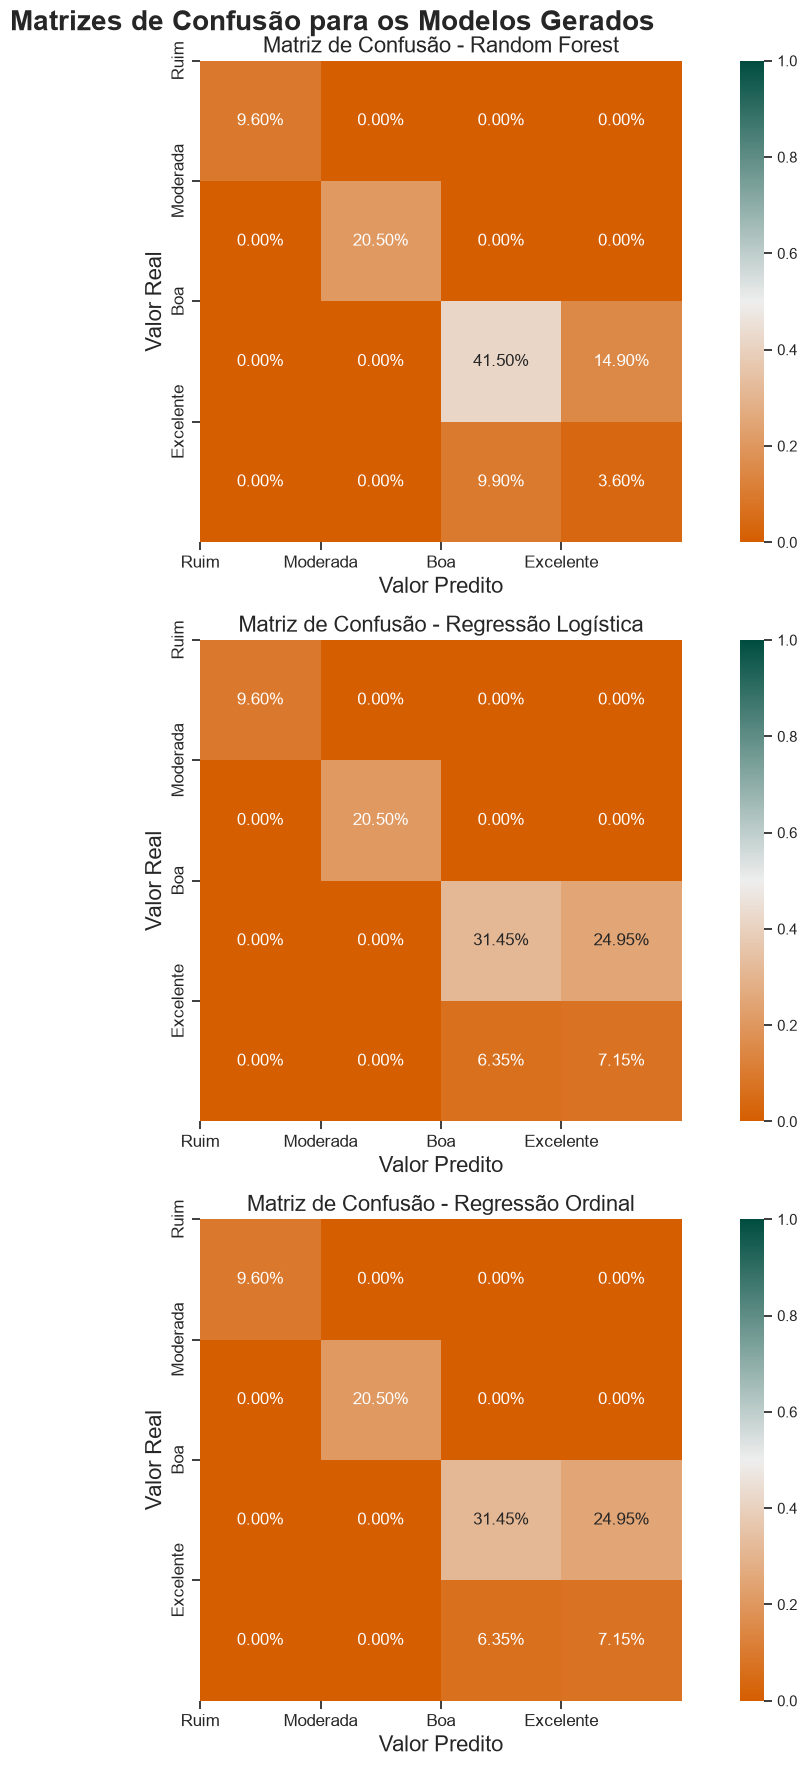

In [48]:
rfMatrix = confusion_matrix(yTeste.values.ravel(), yPredRF, normalize = 'all')
logMatrix = confusion_matrix(yTeste.values.ravel(), yPredLr, normalize = 'all')
ordMatrix = confusion_matrix(yTeste.values.ravel(), yPredOrd, normalize = 'all')

colors = colorPalette(0)
cList = [colors['orange'], '#EEEEEE', colors['green']]
cmap = LinearSegmentedColormap.from_list('orange_to_green', cList)


fig, ax = plt.subplots(3, 1, figsize = (12,18))
plt.suptitle('Matrizes de Confusão para os Modelos Gerados', fontsize = 20, weight = 'bold')

sns.heatmap(rfMatrix,cmap = cmap, annot = True, square = True,
           xticklabels = ['Poor', 'Fair', 'Good', 'Excellent'],
           yticklabels = ['Poor', 'Fair', 'Good', 'Excellent'],
           fmt = '.2%', ax = ax[0], vmin = 0, vmax = 1)
ax[0].set_xticks([0, 1, 2, 3], labels = ['Ruim', 'Moderada', 'Boa', 'Excelente'], fontsize = 12)
ax[0].set_yticks([0, 1, 2, 3], labels = ['Ruim', 'Moderada', 'Boa', 'Excelente'], fontsize = 12)
ax[0].set_ylabel('Valor Real', fontsize = 16)
ax[0].set_xlabel('Valor Predito', fontsize = 16)
ax[0].set_title('Matriz de Confusão - Random Forest', fontsize = 16)

sns.heatmap(logMatrix,cmap = cmap, annot = True, square = True,
           xticklabels = ['Poor', 'Fair', 'Good', 'Excellent'],
           yticklabels = ['Poor', 'Fair', 'Good', 'Excellent'],
           fmt = '.2%', ax = ax[1], vmin = 0, vmax = 1)
ax[1].set_xticks([0, 1, 2, 3], labels = ['Ruim', 'Moderada', 'Boa', 'Excelente'], fontsize = 12)
ax[1].set_yticks([0, 1, 2, 3], labels = ['Ruim', 'Moderada', 'Boa', 'Excelente'], fontsize = 12)
ax[1].set_ylabel('Valor Real', fontsize = 16)
ax[1].set_xlabel('Valor Predito', fontsize = 16)
ax[1].set_title('Matriz de Confusão - Regressão Logística', fontsize = 16)

sns.heatmap(ordMatrix,cmap = cmap, annot = True, square = True,
           xticklabels = ['Poor', 'Fair', 'Good', 'Excellent'],
           yticklabels = ['Poor', 'Fair', 'Good', 'Excellent'],
           fmt = '.2%', ax = ax[2], vmin = 0, vmax = 1)
ax[2].set_xticks([0, 1, 2, 3], labels = ['Ruim', 'Moderada', 'Boa', 'Excelente'], fontsize = 12)
ax[2].set_yticks([0, 1, 2, 3], labels = ['Ruim', 'Moderada', 'Boa', 'Excelente'], fontsize = 12)
ax[2].set_ylabel('Valor Real', fontsize = 16)
ax[2].set_xlabel('Valor Predito', fontsize = 16)
ax[2].set_title('Matriz de Confusão - Regressão Ordinal', fontsize = 16)

plt.tight_layout()
plt.show()

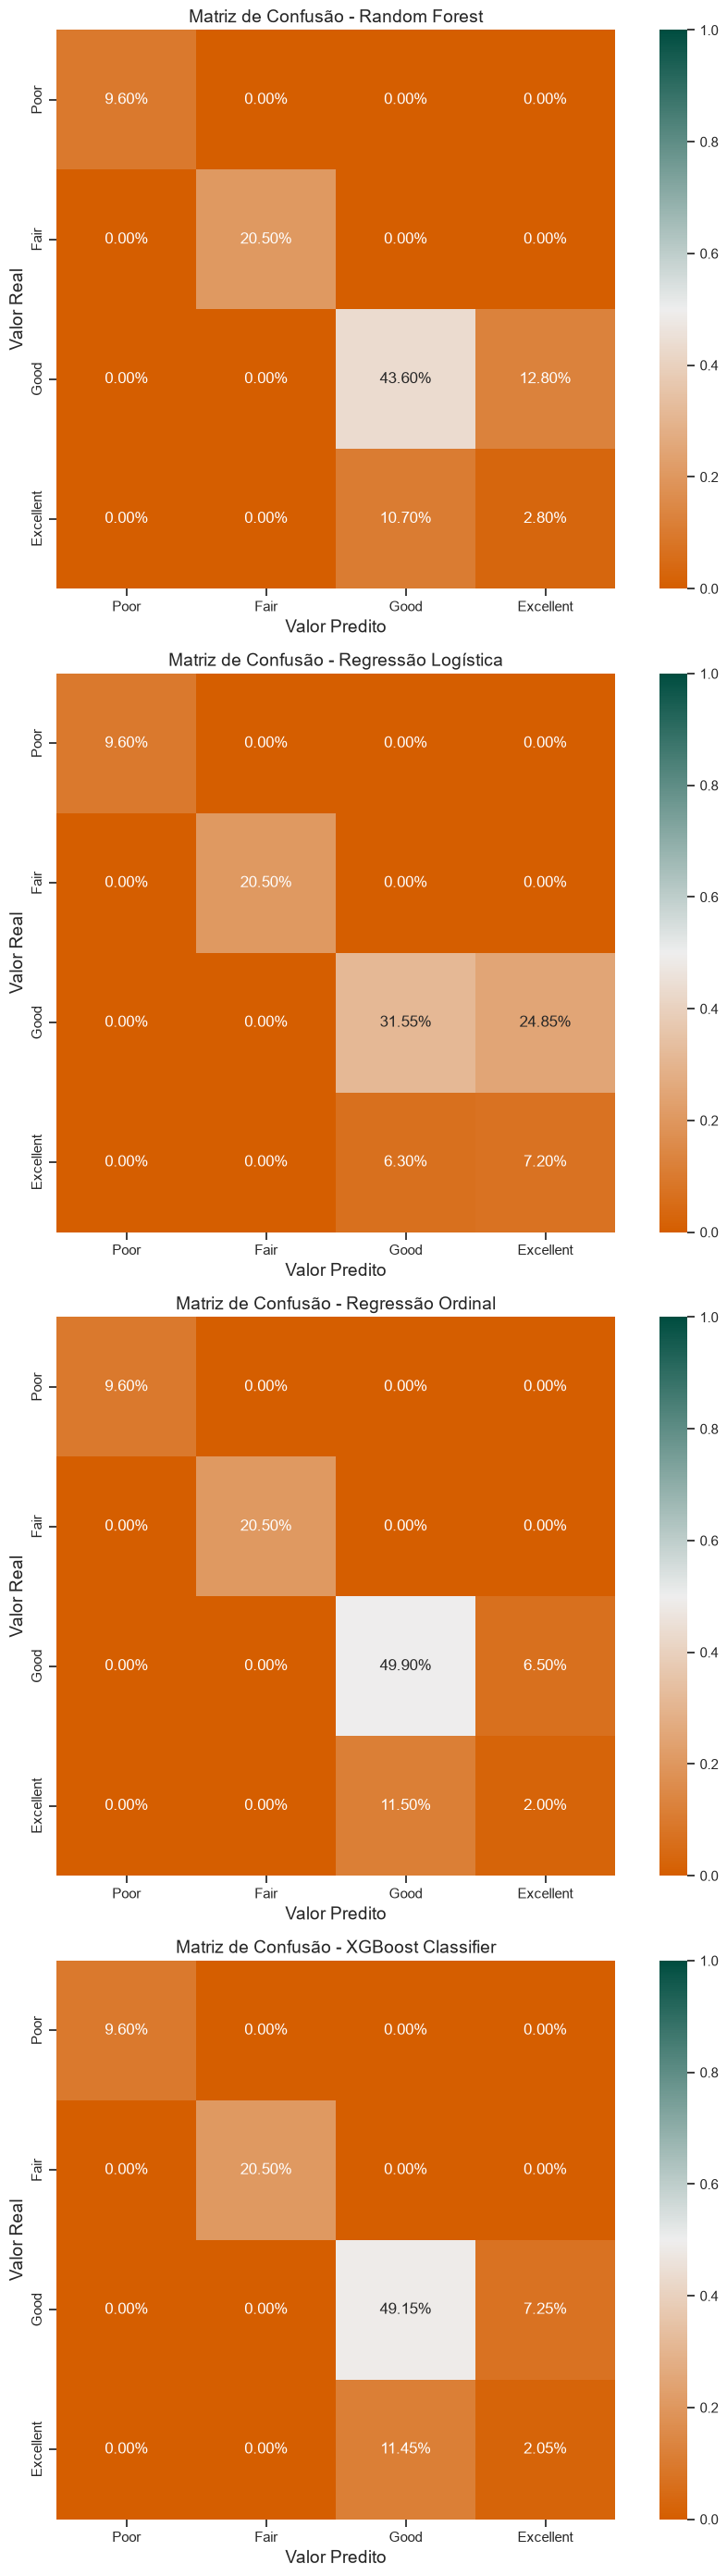

In [130]:
##Matrizes de confusão
rfMatrix = confusion_matrix(yTeste.values.ravel(), yPredRF, normalize='all')
logMatrix = confusion_matrix(yTeste.values.ravel(), yPredLr, normalize='all')
ordMatrix = confusion_matrix(yTeste.values.ravel(), yPredOrd, normalize='all')
xgbMatrix = confusion_matrix(yTeste.values.ravel(), xgbPred, normalize='all') # Added XGBoost matrix

colors = colorPalette(0)
cList = [colors['orange'], '#EEEEEE', colors['green']]
cmap = LinearSegmentedColormap.from_list('orange_to_green', cList)

fig, ax = plt.subplots(4, 1, figsize=(10, 28))

# --- Random Forest ---
sns.heatmap(rfMatrix, cmap=cmap, annot=True, square=True,
            xticklabels=['Poor', 'Fair', 'Good', 'Excellent'],
            yticklabels=['Poor', 'Fair', 'Good', 'Excellent'],
            fmt='.2%', ax=ax[0], vmin=0, vmax=1)
ax[0].set_ylabel('Valor Real', fontsize=14)
ax[0].set_xlabel('Valor Predito', fontsize=14)
ax[0].set_title('Matriz de Confusão - Random Forest', fontsize=14)

# --- Regressão Logística ---
sns.heatmap(logMatrix, cmap=cmap, annot=True, square=True,
            xticklabels=['Poor', 'Fair', 'Good', 'Excellent'],
            yticklabels=['Poor', 'Fair', 'Good', 'Excellent'],
            fmt='.2%', ax=ax[1], vmin=0, vmax=1)
ax[1].set_ylabel('Valor Real', fontsize=14)
ax[1].set_xlabel('Valor Predito', fontsize=14)
ax[1].set_title('Matriz de Confusão - Regressão Logística', fontsize=14)

# --- Regressão Ordinal ---
sns.heatmap(ordMatrix, cmap=cmap, annot=True, square=True,
            xticklabels=['Poor', 'Fair', 'Good', 'Excellent'],
            yticklabels=['Poor', 'Fair', 'Good', 'Excellent'],
            fmt='.2%', ax=ax[2], vmin=0, vmax=1)
ax[2].set_ylabel('Valor Real', fontsize=14)
ax[2].set_xlabel('Valor Predito', fontsize=14)
ax[2].set_title('Matriz de Confusão - Regressão Ordinal', fontsize=14)

# --- XGBoost Classifier ---
sns.heatmap(xgbMatrix, cmap=cmap, annot=True, square=True,
            xticklabels=['Poor', 'Fair', 'Good', 'Excellent'],
            yticklabels=['Poor', 'Fair', 'Good', 'Excellent'],
            fmt='.2%', ax=ax[3], vmin=0, vmax=1)
ax[3].set_ylabel('Valor Real', fontsize=14)
ax[3].set_xlabel('Valor Predito', fontsize=14)
ax[3].set_title('Matriz de Confusão - XGBoost Classifier', fontsize=14)

plt.tight_layout()
plt.show()

Comparando o F1-score dos três modelos junto de suas matrizes de confusão, temos que o modelo de <i>Random Forest</i> apresenta o melhor resultado. Ele consegue, bem como os outros modelos, acertar perfeitamente as observações com qualidade do sono "Ruim" e "Moderada". Ao analisar a qualidade de sono "Boa", ele foi o modelo que menos errou (44% de acertos contra 31,45% dos outros modelos). Esse resultado é ainda melhor se observarmos que a maior parte da amostra está concentrada nas observações dadas como boas. Ele só perde em relação aos modelos de regressão logística e regressão ordinal ao tentar predizer as qualidades de sono "Excelente" (a categoria representa cerca de 13% do conujunto de dados total).

Portanto, seguiremos com ele para avaliar o impacto da ingestão de cafeína sobre a qualidade do sono.

<h2>Avaliando o Impacto da Ingestão de Cafeína na Qualidade do Sono</h2>

Para analisarmos o impacto da ingestão de café sobre a qualidade do sono neste caso, temos que analisar os "valores de <i>shap</i>" (shapley additive explanations), pois o modelo escolhido como mais bem-sucedido foi o modelo de <i>Random Forest</i>. Usaremos a biblioteca shap para isso.

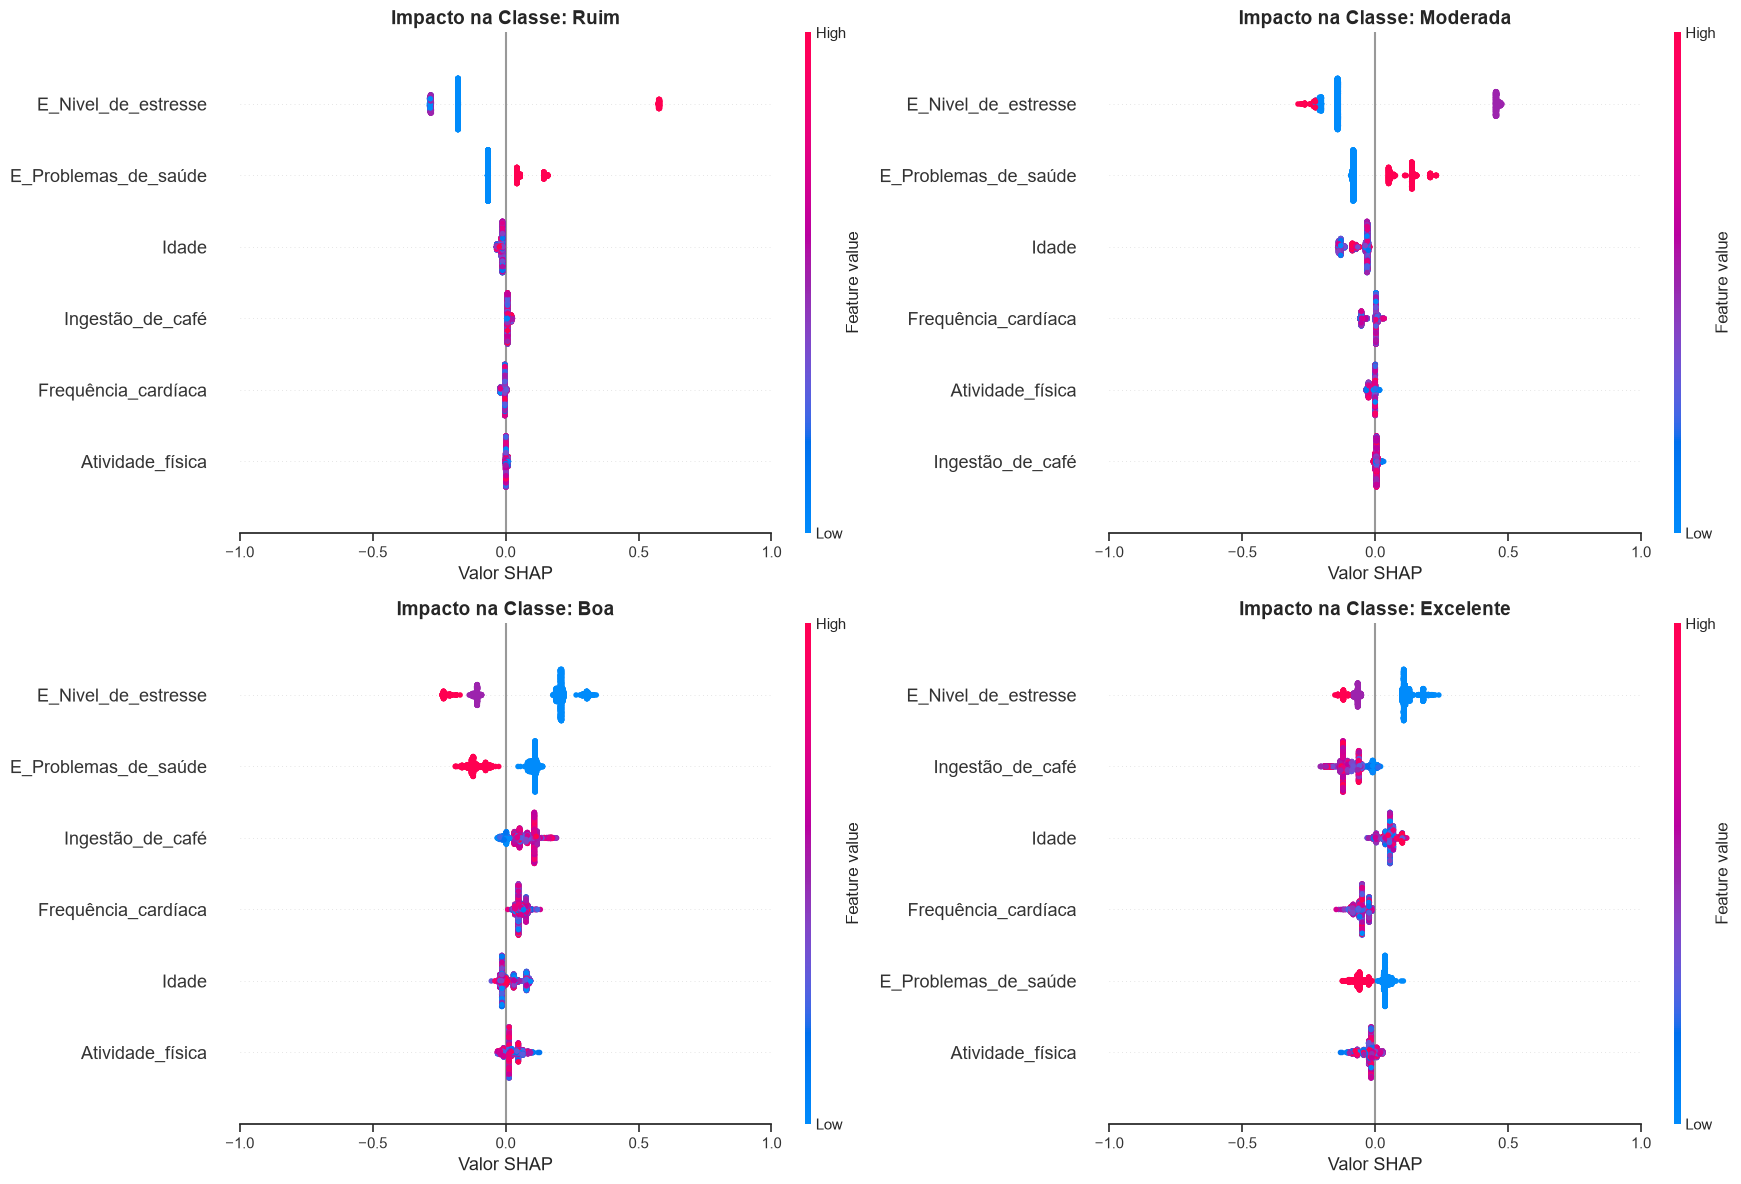

In [49]:
classes = ['Ruim', 'Moderada', 'Boa', 'Excelente'] #Do ordinal Encoder usado anteriormente


fig, ax = plt.subplots(2, 2, figsize = (18,12))
ax = ax.flatten()

for i in range(4):
    plt.sca(ax[i])
    pipeline = gridRf.best_estimator_
    modelo = pipeline.named_steps['classifier']
    expl = shap.TreeExplainer(modelo)
    shapValores = expl.shap_values(xTeste)
    shap.summary_plot(shapValores[:, :, i], xTeste, show = False, plot_size = None)
    ax[i].set_title(f"Impacto na Classe: {classes[i]}", fontsize = 14, weight = 'bold')
    ax[i].set_xlabel(f"Valor SHAP")
    ax[i].set_xticks(np.arange(-1, 1.1, 0.5))
    ax[i].set_xlim(-1,1)
    
fig.tight_layout()
plt.show()

A análise dos gráficos é feita da seguinte maneira:

<ul>
    <li>Todos os pontos representados nos gráficos são observações de clientes (neste caso).</li>
    <li>No eixo vertical temos cada uma das variáveis contidas no modelo, enquanto o eixo horizontal apresenta a escala de valores de shap.</li>
    <li>O eixo horizontal foi parametrizado para conter valores entre -1 e 1. Esses valores são úteis nessa avaliação em específico pois aponta a    contribuição de cada variável na "certeza" que o modelo de <i>Random Forest</i> tinha em cada predição.</li> 
    <li>Cada ponto apresentado no gráfico representa um cliente da subamostra de teste. Quanto mais à direita o ponto, maior a contribuição da variável no momento da predição. Quanto mais à esquerda, menor a contribuição.</li>
    <li>As variáveis estão dispostas em ordem de maior para menor em termos de contribuição, de cima (maior) para baixo (menor) em termos de valor da mádia absoluta.</li>
</ul>

Analisando o gráfico de qualidade de sono excelente, por exemplo, o nível de estresse é a variável que mais contribui para o modelo classificar com mais certeza se o cliente teve uma qualidade de sono dessa mesma classe, sendo que níveis de estresse menores (representado pelos pontos azuis) contribuíram mais do que níveis de estresse maiores e neutros (apresentados pelos pontos vermelho e roxos respectivamente). Atividade física nesta classe foi a variável que menos contribuiu com o modelo para classificar cleintes com excelente qualidade de sono.

Já na classe "Ruim", o nível de estresse continuou sendo a variável de maior contribuição na "certeza" do modelo no momento da classificação. Contudo, os mariores valores de shap (representados pelos pontos mais à direita) foram os casos em que o nível de estresse eram maiores (vermelhos).

A ingestão de café, nossa variável de maior interesse, fica atrás do nível de estresse e de severidade do problema de saúde na maior parte das classes. Ingestão de café aparece como relevante nas clases "Boa" e "Excelente".

<h1>Considerações Finais</h1>

Este trabalho foi realizado com o intuito de ser um <i>checkpoint</i> de aprendizado de uma série de cursos da Alura. Apesar de ser um checkpoint que tem por objetivo colocar em prática a teoria ministrada até este ponto, eu optei por adicionar mais conteúdo construído ao longo dos meus anos cursando economia, como adiscussão do DAG, que possibilita uma discussão de relações causais, que vai além de olhar apenas para as correlações entre variáveis. Também me preocupei em aprender um modelo adicional por conta própria, como a Regressão Ordinal, e uma forma nova de visualizar a contribuição das variáveis na escolha do rótulo pelo modelo escolhido, os "valores de shap".

O banco de dados foi extraído do <i>Kaggle</i> e fornecido pela própia escola. De acordo com a descrição contida o <i>Kaggle</i>, os dados são originários da <i>GlobalCoffeeHealth dataset</i>, um conjunto gerado sintéticamente. Por isso, quando confrontamos o DAG apresentado no início do trabalho com as correlações geradas no <i>heatmap</i> de correlações também no início do trabalho, as visualizações parecem não se encontrar. Mais do que simplesmente importar pacotes e incluir dados em um modelo, mais importante é entender a relação causal entre as variáveis para escolher com mais certeza o modelo apropriado. De nada vale uma alta pontuação de um modelo se este modelo foi escolhido erroneamente, ignorando premissas básicas intrínsecas aos dados.

Como pudemos observar, as relações entre as variáveis presentes no banco de dados é bastante complexa. Além de diversas variáveis explicativas afetarem a variável explicada diretamente e indiretamente, é possível notar com frequência que as variáveis se retroalimentam, como em Ingestão_de_café <--> Qualidade_do_sono. Nenhum dos modelos ensinados até o momento conseguem capturar essas relações bidirecionais, como uma aplicação de variáveis instrumentais.

Com relação ao objetivo do estudo, foi possível notar que na maioria dos casos de qualidade do sono ("Ruim", "Moderada" e "Boa", que representam cerca de 86% do conjunto de dados) o nível de estresse e severidade dos problemas de saúde acabam tendo muito mais participação do que a ingestão de café em si. O único cenário em que a ingestão de café assume mais protagonismo é ao avaliar a classe "Excelente" de sono, onde a baixa ingestão de café combianda com os outros fatores incluídos no modelo, contribui para a melhora da qualidade do sono.